In [8]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/abdelmdz/uk-dale/ukdale.h5


In [9]:
# ============================================================================
# CELL 1: Installation et imports
# ============================================================================

!pip install joblib seaborn scikit-learn -q

import os
import warnings
import logging
import joblib
import json
import glob
from datetime import datetime, timedelta

os.environ['HDF5_PLUGIN_PATH'] = '/tmp/hdf5_plugins'
os.makedirs('/tmp/hdf5_plugins', exist_ok=True)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['CUDA_DEVICE_ORDER'] = 'PCI_BUS_ID'

warnings.filterwarnings('ignore')
logging.getLogger('tensorflow').setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import h5py

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from tensorflow.keras import regularizers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

print('='*60)
print('Configuration')
print('='*60)
print(f'TensorFlow : {tf.__version__}')
print(f'GPU disponible : {tf.config.list_physical_devices("GPU")}')
print(f'NumPy : {np.__version__}')
print(f'Pandas : {pd.__version__}')
print(f'h5py : {h5py.__version__}')

Configuration
TensorFlow : 2.19.0
GPU disponible : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
NumPy : 2.0.2
Pandas : 2.3.3
h5py : 3.15.1


In [10]:
# ============================================================================
# CELL 2: Trouver automatiquement le fichier UK-DALE
# ============================================================================

print("Recherche du fichier UK-DALE...")

if os.path.exists('/kaggle/input'):
    print("\nContenu de /kaggle/input:")
    for item in os.listdir('/kaggle/input'):
        print(f"  - {item}")
        item_path = f'/kaggle/input/{item}'
        if os.path.isdir(item_path):
            files = os.listdir(item_path)[:5]
            if files:
                print(f"    Fichiers: {files}")

h5_files = glob.glob('/kaggle/input/**/*.h5', recursive=True)
if h5_files:
    print(f"\nFichiers .h5 trouvés:")
    for f in h5_files:
        print(f"  - {f}")
    H5_PATH = h5_files[0]
    print(f"\n✅ Utilisation de: {H5_PATH}")
else:
    print("\n❌ Aucun fichier .h5 trouvé!")
    H5_PATH = None

Recherche du fichier UK-DALE...

Contenu de /kaggle/input:
  - datasets
    Fichiers: ['abdelmdz']
  - notebooks
    Fichiers: ['sakunrasilka']

Fichiers .h5 trouvés:
  - /kaggle/input/datasets/abdelmdz/uk-dale/ukdale.h5

✅ Utilisation de: /kaggle/input/datasets/abdelmdz/uk-dale/ukdale.h5


In [11]:
# ============================================================================
# CELL 3 MODIFIÉE: Configuration centrale avec house 1
# ============================================================================

class Config:

    WINDOW_SIZE = 99
    BATCH_SIZE  = 1024
    EPOCHS      = 50
    LR          = 1e-3
    VAL_SPLIT   = 0.15
    SEED        = 42

    UKDALE_HOUSES = {
        'house_1': {  # Maison d'entraînement principale
            'name': 'UKDALE-1',
            'house_id': 1,
            'train': ('2013-12-01', '2014-03-31'),  # 4 mois d'entraînement
            'test':  ('2014-04-01', '2014-05-01'),  # 1 mois de validation
            'appliances': {
                'Fridge':          {'meter': 2, 'threshold':   50, 'color': '#FF6B6B'},
                'Dishwasher':      {'meter': 4, 'threshold':   10, 'color': '#4ECDC4'},
                'Microwave':       {'meter': 6, 'threshold':  200, 'color': '#45B7D1'},
                'Washing_Machine': {'meter': 3, 'threshold':   20, 'color': '#96CEB4'},
                'Kettle':          {'meter': 5, 'threshold': 2000, 'color': '#FFE194'},
                'Electric_Oven':   {'meter': 7, 'threshold':  500, 'color': '#B19CD9'},
            }
        },
        'house_2': {
            'name': 'UKDALE-2',
            'house_id': 2,
            'test':  ('2013-05-01', '2013-08-01'),  # Période de test complète
            'appliances': {
                'Fridge':          {'meter': 2, 'threshold':   50, 'color': '#FF6B6B'},
                'Dishwasher':      {'meter': 4, 'threshold':   10, 'color': '#4ECDC4'},
                'Microwave':       {'meter': 6, 'threshold':  200, 'color': '#45B7D1'},
                'Rice_Cooker':     {'meter': 8, 'threshold':  300, 'color': '#96CEB4'},
                'Kettle':          {'meter': 5, 'threshold': 2000, 'color': '#FFE194'},
                'Washing_Machine': {'meter': 3, 'threshold':   20, 'color': '#B19CD9'},
            }
        },
        'house_3': {
            'name': 'UKDALE-3',
            'house_id': 3,
            'test':  ('2013-05-01', '2013-08-01'),
            'appliances': {
                'Fridge':          {'meter': 2, 'threshold':   50, 'color': '#FF6B6B'},
                'Dishwasher':      {'meter': 4, 'threshold':   10, 'color': '#4ECDC4'},
                'Microwave':       {'meter': 6, 'threshold':  200, 'color': '#45B7D1'},
                'Kettle':          {'meter': 5, 'threshold': 2000, 'color': '#FFE194'},
                'Washing_Machine': {'meter': 3, 'threshold':   20, 'color': '#96CEB4'},
            }
        },
        'house_4': {
            'name': 'UKDALE-4',
            'house_id': 4,
            'test':  ('2013-05-01', '2013-08-01'),
            'appliances': {
                'Fridge':          {'meter': 2, 'threshold':   50, 'color': '#FF6B6B'},
                'Dishwasher':      {'meter': 4, 'threshold':   10, 'color': '#4ECDC4'},
                'Microwave':       {'meter': 6, 'threshold':  200, 'color': '#45B7D1'},
                'Kettle':          {'meter': 5, 'threshold': 2000, 'color': '#FFE194'},
            }
        },
        'house_5': {
            'name': 'UKDALE-5',
            'house_id': 5,
            'test':  ('2014-05-01', '2014-08-01'),
            'appliances': {
                'Fridge':          {'meter': 2, 'threshold':   50, 'color': '#FF6B6B'},
                'Dishwasher':      {'meter': 4, 'threshold':   10, 'color': '#4ECDC4'},
                'Microwave':       {'meter': 6, 'threshold':  200, 'color': '#45B7D1'},
                'Kettle':          {'meter': 5, 'threshold': 2000, 'color': '#FFE194'},
                'Washing_Machine': {'meter': 3, 'threshold':   20, 'color': '#96CEB4'},
            }
        }
    }

    FREQ = '6s'

    ON_THRESHOLDS = {
        'Fridge':          50,
        'Dishwasher':      10,
        'Microwave':      200,
        'Electric_Oven':  500,
        'Kettle':        2000,
        'Washing_Machine': 20,
        'Rice_Cooker':    300,
    }

    H5_PATH = None
    TRAIN_HOUSE = 'house_1'  # Maison d'entraînement par défaut
    TEST_HOUSE = 'house_2'   # Maison de test par défaut

    @classmethod
    def get_threshold(cls, appliance_name):
        return cls.ON_THRESHOLDS.get(appliance_name.split('_')[0], 50)


if 'H5_PATH' in globals() and H5_PATH:
    Config.H5_PATH = H5_PATH

tf.random.set_seed(Config.SEED)
np.random.seed(Config.SEED)

print("Configuration:")
print(f"  Window size : {Config.WINDOW_SIZE}")
print(f"  Batch size  : {Config.BATCH_SIZE}")
print(f"  Epochs      : {Config.EPOCHS}")
print(f"  Train house : {Config.TRAIN_HOUSE}")
print(f"  Test house  : {Config.TEST_HOUSE}")
print(f"  H5_PATH     : {Config.H5_PATH}")

Configuration:
  Window size : 99
  Batch size  : 1024
  Epochs      : 50
  Train house : house_1
  Test house  : house_2
  H5_PATH     : /kaggle/input/datasets/abdelmdz/uk-dale/ukdale.h5


In [12]:
# ============================================================================
# CELL 4 MODIFIÉE: Chargeur de données UK-DALE avec support test uniquement
# ============================================================================

class UKDALEDataLoader:

    def __init__(self, h5_path):
        self.h5_path = h5_path

    def read_meter_pandas(self, building, meter):
        try:
            key = f'building{building}/elec/{meter}'
            s = pd.read_hdf(self.h5_path, key=key)
            if isinstance(s, pd.DataFrame):
                s = s.iloc[:, 0]
            s = s.astype(np.float32)
            s = s[~s.index.duplicated(keep='first')]
            return s.sort_index()
        except Exception as e:
            # print(f"  Erreur lecture {key}: {e}")
            return None

    def load_house_train(self, house_key):
        """Charge une maison pour l'entraînement (avec train/test split)"""
        if house_key not in Config.UKDALE_HOUSES:
            raise ValueError(f"Maison {house_key} non trouvée")

        house_config = Config.UKDALE_HOUSES[house_key]
        house_id = house_config['house_id']
        
        # Vérifier si la config a train/test
        if 'train' not in house_config:
            print(f"⚠️  {house_key} n'a pas de période d'entraînement définie")
            return None
            
        train_start, train_end = house_config['train']
        test_start, test_end = house_config.get('test', (None, None))
        appliances_config = house_config['appliances']

        print(f"\n{'='*50}")
        print(f"CHARGEMENT TRAIN: {house_config['name']} (maison {house_id})")
        print(f"{'='*50}")
        print(f"Période train: {train_start} → {train_end}")
        if test_start:
            print(f"Période test:  {test_start} → {test_end}")
        print(f"{'='*50}")

        if not os.path.exists(self.h5_path):
            raise FileNotFoundError(f"Fichier non trouvé: {self.h5_path}")

        # Charger tous les compteurs
        all_meters = self._load_all_meters(house_id, appliances_config)
        
        if not all_meters:
            raise ValueError(f"Aucune donnée chargée pour maison {house_id}")

        # Créer la grille temporelle
        grid, train_mask, test_mask = self._create_time_grid(
            all_meters, train_start, train_end, test_start, test_end
        )
        
        # Créer le DataFrame
        df = self._create_dataframe(all_meters, grid)
        
        # Split train/test
        train_df = df[train_mask.values].copy() if train_mask is not None else pd.DataFrame()
        test_df = df[test_mask.values].copy() if test_mask is not None else pd.DataFrame()

        print(f"\nTrain : {len(train_df)} échantillons")
        if len(test_df) > 0:
            print(f"Test  : {len(test_df)} échantillons")

        # Statistiques
        available_monitored = [m for m in self._get_monitored_meters(appliances_config) 
                              if m in df.columns]
        other_meters = [m for m in df.columns if m not in available_monitored]

        if available_monitored and len(train_df) > 0:
            print("\nStatistiques des appliances (train):")
            for meter in available_monitored:
                if meter in train_df.columns:
                    on_pct = (train_df[meter] > 10).mean() * 100
                    print(f"  {meter}: moy={train_df[meter].mean():.1f}W  "
                          f"max={train_df[meter].max():.1f}W  "
                          f"ON={on_pct:.1f}%")

        return {
            'name': house_config['name'],
            'house_id': house_id,
            'house_key': house_key,
            'train_df': train_df,
            'test_df': test_df,
            'grid': grid,
            'monitored_meters': available_monitored,
            'monitored_appliances': appliances_config,
            'other_meters': other_meters,
            'all_meters': list(df.columns),
        }

    def load_house_test(self, house_key):
        """Charge une maison uniquement pour le test (pas de données train)"""
        if house_key not in Config.UKDALE_HOUSES:
            raise ValueError(f"Maison {house_key} non trouvée")

        house_config = Config.UKDALE_HOUSES[house_key]
        house_id = house_config['house_id']
        
        # Vérifier si la config a une période de test
        if 'test' not in house_config:
            print(f"⚠️  {house_key} n'a pas de période de test définie")
            return None
            
        test_start, test_end = house_config['test']
        appliances_config = house_config['appliances']

        print(f"\n{'='*50}")
        print(f"CHARGEMENT TEST: {house_config['name']} (maison {house_id})")
        print(f"{'='*50}")
        print(f"Période test: {test_start} → {test_end}")
        print(f"{'='*50}")

        if not os.path.exists(self.h5_path):
            raise FileNotFoundError(f"Fichier non trouvé: {self.h5_path}")

        # Charger tous les compteurs
        all_meters = self._load_all_meters(house_id, appliances_config)
        
        if not all_meters:
            raise ValueError(f"Aucune donnée chargée pour maison {house_id}")

        # Créer la grille temporelle (uniquement pour la période de test)
        grid, _, test_mask = self._create_time_grid(
            all_meters, None, None, test_start, test_end
        )
        
        # Créer le DataFrame
        df = self._create_dataframe(all_meters, grid)
        
        # Extraire uniquement les données de test
        test_df = df[test_mask.values].copy() if test_mask is not None else pd.DataFrame()

        print(f"\nTest : {len(test_df)} échantillons")

        # Statistiques
        available_monitored = [m for m in self._get_monitored_meters(appliances_config) 
                              if m in df.columns]
        other_meters = [m for m in df.columns if m not in available_monitored]

        if available_monitored and len(test_df) > 0:
            print("\nStatistiques des appliances (test):")
            for meter in available_monitored:
                if meter in test_df.columns:
                    on_pct = (test_df[meter] > 10).mean() * 100
                    print(f"  {meter}: moy={test_df[meter].mean():.1f}W  "
                          f"max={test_df[meter].max():.1f}W  "
                          f"ON={on_pct:.1f}%")

        return {
            'name': house_config['name'],
            'house_id': house_id,
            'house_key': house_key,
            'test_df': test_df,
            'grid': grid,
            'monitored_meters': available_monitored,
            'monitored_appliances': appliances_config,
            'other_meters': other_meters,
            'all_meters': list(df.columns),
        }

    def _load_all_meters(self, house_id, appliances_config):
        """Charge tous les compteurs disponibles"""
        monitored_meters_list = [f'meter{info["meter"]}' for info in appliances_config.values()]
        other_meters_to_try = [f'meter{i}' for i in range(1, 30)
                              if f'meter{i}' not in monitored_meters_list]

        all_meters = {}

        print("\nChargement des compteurs monitorés:")
        for meter_name in monitored_meters_list:
            print(f"  Lecture {meter_name}...", end='')
            series = self.read_meter_pandas(house_id, meter_name)
            if series is not None and len(series) > 0:
                all_meters[meter_name] = series
                print(f" ✓ {len(series)} points")
            else:
                print(f" ✗")

        print("\nChargement d'autres compteurs (pour le bruit):")
        for meter_name in other_meters_to_try[:10]:
            print(f"  Lecture {meter_name}...", end='')
            series = self.read_meter_pandas(house_id, meter_name)
            if series is not None and len(series) > 0:
                all_meters[meter_name] = series
                print(f" ✓ {len(series)} points")
            else:
                print(f" ✗")

        print(f"\n✅ {len(all_meters)} compteurs chargés")
        return all_meters

    def _create_time_grid(self, all_meters, train_start, train_end, test_start, test_end):
        """Crée la grille temporelle et les masques train/test"""
        start_dates = [s.index.min() for s in all_meters.values()]
        end_dates = [s.index.max() for s in all_meters.values()]
        common_start = max(start_dates)
        common_end = min(end_dates)

        grid = pd.date_range(start=common_start, end=common_end, freq=Config.FREQ)
        print(f"Grille créée: {len(grid)} points")

        # Créer les masques
        grid_series = pd.Series(grid)
        train_mask = None
        test_mask = None
        
        if train_start and train_end:
            train_mask = (grid_series >= train_start) & (grid_series <= train_end)
        
        if test_start and test_end:
            test_mask = (grid_series >= test_start) & (grid_series <= test_end)

        return grid, train_mask, test_mask

    def _create_dataframe(self, all_meters, grid):
        """Crée le DataFrame à partir des séries temporelles"""
        resampled = {}
        for meter, series in all_meters.items():
            resampled[meter] = series.reindex(
                grid, method='nearest', tolerance=Config.FREQ
            ).fillna(0)

        return pd.DataFrame(resampled)

    def _get_monitored_meters(self, appliances_config):
        """Retourne la liste des compteurs monitorés"""
        return [f'meter{info["meter"]}' for info in appliances_config.values()]

In [13]:
# ============================================================================
# CELL 5 MODIFIÉE: Chargement des données (train sur house_1)
# ============================================================================

if Config.H5_PATH and os.path.exists(Config.H5_PATH):
    loader = UKDALEDataLoader(Config.H5_PATH)
    print("✅ Chargeur initialisé")

    # Charger la maison d'entraînement (house_1)
    print(f"\n📚 CHARGEMENT MAISON D'ENTRAÎNEMENT: {Config.TRAIN_HOUSE}")
    try:
        train_data = loader.load_house_train(Config.TRAIN_HOUSE)
        print(f"\n✅ Entraînement chargé: {train_data['name']}")
        print(f"   Train shape: {train_data['train_df'].shape}")
        print(f"   Test shape:  {train_data['test_df'].shape}")
    except Exception as e:
        print(f"\n❌ Erreur chargement train: {e}")
        train_data = None

    # Charger la maison de test (par défaut house_2)
    print(f"\n🔬 CHARGEMENT MAISON DE TEST: {Config.TEST_HOUSE}")
    try:
        test_data = loader.load_house_test(Config.TEST_HOUSE)
        print(f"\n✅ Test chargé: {test_data['name']}")
        print(f"   Test shape: {test_data['test_df'].shape}")
    except Exception as e:
        print(f"\n❌ Erreur chargement test: {e}")
        test_data = None

    DATA_TRAIN = train_data
    DATA_TEST = test_data
    
else:
    print("❌ Fichier non trouvé")
    loader = None
    DATA_TRAIN = None
    DATA_TEST = None

✅ Chargeur initialisé

📚 CHARGEMENT MAISON D'ENTRAÎNEMENT: house_1

CHARGEMENT TRAIN: UKDALE-1 (maison 1)
Période train: 2013-12-01 → 2014-03-31
Période test:  2014-04-01 → 2014-05-01

Chargement des compteurs monitorés:
  Lecture meter2... ✓ 21281331 points
  Lecture meter4... ✓ 4539118 points
  Lecture meter6... ✓ 19819392 points
  Lecture meter3... ✓ 21281208 points
  Lecture meter5... ✓ 19555935 points
  Lecture meter7... ✓ 19763329 points

Chargement d'autres compteurs (pour le bruit):
  Lecture meter1... ✓ 21837636 points
  Lecture meter8... ✓ 21449386 points
  Lecture meter9... ✓ 19543268 points
  Lecture meter10... ✓ 18881051 points
  Lecture meter11... ✓ 19404267 points
  Lecture meter12... ✓ 19381298 points
  Lecture meter13... ✓ 19406625 points
  Lecture meter14... ✓ 4143648 points
  Lecture meter15... ✓ 4157704 points
  Lecture meter16... ✓ 13351860 points

✅ 16 compteurs chargés
Grille créée: 22950712 points

Train : 1727400 échantillons
Test  : 432000 échantillons

Statis

In [14]:
# ============================================================================
# CELL 6 MODIFIÉE: Fonction pour changer la maison de test
# ============================================================================

def set_test_house(house_key):
    """
    Change la maison de test et recharge les données
    Maisons disponibles: 'house_1', 'house_2', 'house_3', 'house_4', 'house_5'
    """
    global DATA_TEST, Config, loader
    
    if house_key not in Config.UKDALE_HOUSES:
        print(f"❌ Maison {house_key} non disponible. Choix: {list(Config.UKDALE_HOUSES.keys())}")
        return False
    
    if loader is None:
        print("❌ Chargeur non initialisé")
        return False
    
    print(f"\n{'='*60}")
    print(f"CHANGEMENT MAISON DE TEST: {Config.TEST_HOUSE} → {house_key}")
    print(f"{'='*60}")
    
    # Mettre à jour la configuration
    Config.TEST_HOUSE = house_key
    
    # Recharger les données de test
    try:
        DATA_TEST = loader.load_house_test(house_key)
        print(f"\n✅ Test chargé: {DATA_TEST['name']}")
        print(f"   Test shape: {DATA_TEST['test_df'].shape}")
        return True
    except Exception as e:
        print(f"\n❌ Erreur chargement test: {e}")
        DATA_TEST = None
        return False


def list_available_houses():
    """Affiche toutes les maisons disponibles"""
    print("\n" + "="*60)
    print("MAISONS DISPONIBLES")
    print("="*60)
    for key, config in Config.UKDALE_HOUSES.items():
        status = "✓" if key == Config.TEST_HOUSE else " "
        has_test = 'test' in config
        has_train = 'train' in config
        print(f"  [{status}] {key}: {config['name']}  "
              f"(Train: {'✓' if has_train else '✗'}, "
              f"Test: {'✓' if has_test else '✗'})")


print("✅ Fonctions ajoutées:")
print("  - set_test_house(house_key): Change la maison de test")
print("  - list_available_houses(): Liste les maisons disponibles")

✅ Fonctions ajoutées:
  - set_test_house(house_key): Change la maison de test
  - list_available_houses(): Liste les maisons disponibles


In [15]:
# ============================================================================
# CELL 7: Test des fonctions de changement de maison
# ============================================================================

print("\n" + "="*60)
print("TEST DES FONCTIONS DE CHANGEMENT DE MAISON")
print("="*60)

# Lister les maisons disponibles
list_available_houses()

# Afficher la maison de test actuelle
print(f"\n🏠 Maison de test actuelle: {Config.TEST_HOUSE}")

# Exemple: Changer pour house_3
print("\n" + "="*60)
print("ESSAI DE CHANGEMENT POUR house_3")
print("="*60)
set_test_house('house_3')


TEST DES FONCTIONS DE CHANGEMENT DE MAISON

MAISONS DISPONIBLES
  [ ] house_1: UKDALE-1  (Train: ✓, Test: ✓)
  [✓] house_2: UKDALE-2  (Train: ✗, Test: ✓)
  [ ] house_3: UKDALE-3  (Train: ✗, Test: ✓)
  [ ] house_4: UKDALE-4  (Train: ✗, Test: ✓)
  [ ] house_5: UKDALE-5  (Train: ✗, Test: ✓)

🏠 Maison de test actuelle: house_2

ESSAI DE CHANGEMENT POUR house_3

CHANGEMENT MAISON DE TEST: house_2 → house_3

CHARGEMENT TEST: UKDALE-3 (maison 3)
Période test: 2013-05-01 → 2013-08-01

Chargement des compteurs monitorés:
  Lecture meter2... ✓ 515845 points
  Lecture meter4... ✓ 517595 points
  Lecture meter6... ✗
  Lecture meter5... ✓ 517957 points
  Lecture meter3... ✓ 517434 points

Chargement d'autres compteurs (pour le bruit):
  Lecture meter1... ✓ 512327 points
  Lecture meter7... ✗
  Lecture meter8... ✗
  Lecture meter9... ✗
  Lecture meter10... ✗
  Lecture meter11... ✗
  Lecture meter12... ✗
  Lecture meter13... ✗
  Lecture meter14... ✗
  Lecture meter15... ✗

✅ 5 compteurs chargés
Gril

True

In [16]:
# ============================================================================
# CELL 7.5: Fonctions NILM manquantes
# ============================================================================

# ============================================================================
# Création des fenêtres glissantes
# ============================================================================

def create_windows(data, window_size=Config.WINDOW_SIZE, target_type='point'):
    values = data.values if isinstance(data, pd.Series) else data
    values = values.astype(np.float32)

    pad_width     = window_size // 2
    values_padded = np.pad(values, (pad_width, pad_width),
                           'constant', constant_values=0)

    X, y = [], []
    for i in range(len(values)):
        x_win = values_padded[i:i + window_size]
        y_val = values[i] if target_type == 'point' else values_padded[i:i + window_size]
        X.append(x_win)
        y.append(y_val)

    X = np.array(X, dtype=np.float32)[..., np.newaxis]
    y = np.array(y, dtype=np.float32)
    return X, y

print("✅ create_windows() défini.")


# ============================================================================
# Métriques NILM
# ============================================================================

class NILMMetrics:

    @staticmethod
    def estimation_accuracy(y_true, y_pred):
        numerator   = np.sum(np.abs(y_true - y_pred))
        denominator = 2 * np.sum(y_true)
        if denominator == 0:
            return 1.0 if numerator == 0 else 0.0
        return np.clip(1 - numerator / denominator, 0, 1)

    @staticmethod
    def f_measure(y_true, y_pred, threshold):
        y_true_bin = (y_true > threshold).astype(int)
        y_pred_bin = (y_pred > threshold).astype(int)
        cm = confusion_matrix(y_true_bin, y_pred_bin, labels=[0, 1])
        if cm.shape != (2, 2):
            return 0.0
        tn, fp, fn, tp = cm.ravel()
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall    = tp / (tp + fn) if (tp + fn) > 0 else 0
        return (2 * precision * recall / (precision + recall)
                if (precision + recall) > 0 else 0)

    @staticmethod
    def overall_estimation_accuracy(all_true, all_pred):
        total_num   = sum(np.sum(np.abs(t - p)) for t, p in zip(all_true, all_pred))
        total_denom = 2 * sum(np.sum(t) for t in all_true)
        if total_denom == 0:
            return 1.0 if total_num == 0 else 0.0
        return np.clip(1 - total_num / total_denom, 0, 1)

print("✅ NILMMetrics défini.")


# ============================================================================
# Architectures robustes Seq2Point et Seq2Seq
# ============================================================================

def create_robust_seq2point(window_size=Config.WINDOW_SIZE, l2_reg=1e-4):
    """
    Seq2Point robuste :
      - BatchNormalization après chaque Conv1D
      - Dropout(0.3) + Dropout(0.2)
      - L2 regularization sur Conv + Dense
    """
    inp = keras.Input(shape=(window_size, 1), name='mains_input')

    x = layers.Conv1D(32, 10, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(inp)
    x = layers.BatchNormalization()(x)

    x = layers.Conv1D(32, 8, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv1D(48, 6, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv1D(64, 5, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv1D(64, 5, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)

    x = layers.Flatten()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(512, activation='relu',
                     kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.Dropout(0.2)(x)
    output = layers.Dense(1, activation='linear', name='power_output')(x)

    return keras.Model(inputs=inp, outputs=output, name='seq2point_robust')


def create_robust_seq2seq(window_size=Config.WINDOW_SIZE, l2_reg=1e-4):
    """
    Seq2Seq robuste (même stratégie anti-overfitting).
    """
    inp = keras.Input(shape=(window_size, 1), name='mains_input')

    x = layers.Conv1D(32, 10, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(inp)
    x = layers.BatchNormalization()(x)

    x = layers.Conv1D(32, 8, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv1D(48, 6, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv1D(64, 5, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv1D(64, 5, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)

    x = layers.Flatten()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(512, activation='relu',
                     kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.Dropout(0.2)(x)
    output = layers.Dense(window_size, activation='linear', name='seq_output')(x)

    return keras.Model(inputs=inp, outputs=output, name='seq2seq_robust')


# Résumé
m_s2p = create_robust_seq2point()
m_s2s = create_robust_seq2seq()
print(f"\n[Seq2Point] Paramètres : {m_s2p.count_params():,}")
print(f"[Seq2Seq]   Paramètres : {m_s2s.count_params():,}")
print("\nTechniques anti-overfitting :")
print("  ✓ BatchNormalization après chaque Conv1D")
print("  ✓ Dropout(0.3) + Dropout(0.2)")
print("  ✓ L2 regularization (λ=1e-4)")
print("  ✓ CosineDecay learning rate")
print("  ✓ Pas d'early stopping — epochs fixes")


# ============================================================================
# Fonction d'entraînement robuste
# ============================================================================

def train_appliance_robust(train_mains, train_appliance,
                           appliance_name, model_type='seq2point',
                           epochs=60):
    print(f"\n{'='*55}")
    print(f"  {model_type.upper()} — {appliance_name}  ({epochs} epochs)")
    print(f"{'='*55}")

    # Normalisation
    mains_scaler = StandardScaler()
    app_scaler   = StandardScaler()
    mains_norm   = mains_scaler.fit_transform(train_mains.reshape(-1, 1)).flatten()
    app_norm     = app_scaler.fit_transform(train_appliance.reshape(-1, 1)).flatten()

    # Fenêtres glissantes
    X, _ = create_windows(mains_norm, target_type='point')
    min_len = min(len(X), len(app_norm))
    X       = X[:min_len]

    if model_type == 'seq2point':
        y_target = app_norm[:min_len]
    else:
        pad    = Config.WINDOW_SIZE // 2
        padded = np.pad(app_norm, (pad, pad), 'constant')
        y_target = np.array([padded[i:i + Config.WINDOW_SIZE]
                             for i in range(min_len)], dtype=np.float32)

    # Split train / validation
    val_size       = int(Config.VAL_SPLIT * len(X))
    X_train, X_val = X[:-val_size], X[-val_size:]
    y_train, y_val = y_target[:-val_size], y_target[-val_size:]
    print(f"  Train : {len(X_train):,}  |  Val : {len(X_val):,}")

    # Modèle
    model = (create_robust_seq2point() if model_type == 'seq2point'
             else create_robust_seq2seq())

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='mse',
        metrics=['mae']
    )

    ckpt_path = f'model_{appliance_name}_{model_type}_best.keras'
    cb_list = [
        callbacks.ModelCheckpoint(
            filepath=ckpt_path,
            monitor='val_loss',
            save_best_only=True,
            verbose=0
        ),
    ]

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=Config.BATCH_SIZE,
        callbacks=cb_list,
        verbose=1
    )

    # Recharger le meilleur checkpoint
    if os.path.exists(ckpt_path):
        model = keras.models.load_model(ckpt_path)
        print(f"\n  ✅ Meilleur modèle rechargé depuis {ckpt_path}")

    return {
        'model':        model,
        'mains_scaler': mains_scaler,
        'app_scaler':   app_scaler,
        'history':      history.history,
    }

print("\n✅ train_appliance_robust() définie")


# ============================================================================
# Fonction de prédiction
# ============================================================================

def predict_appliance(mains_series, model_info, model_type='seq2point'):
    model        = model_info['model']
    mains_scaler = model_info['mains_scaler']
    app_scaler   = model_info['app_scaler']

    mains_norm = mains_scaler.transform(
        mains_series.values.reshape(-1, 1)
    ).flatten()

    X, _ = create_windows(mains_norm, target_type='point')

    predictions = []
    for i in range(0, len(X), 1024):
        batch = X[i:i + 1024]
        pred  = model.predict(batch, verbose=0)
        if model_type == 'seq2point':
            predictions.append(pred.flatten())
        else:
            mid = Config.WINDOW_SIZE // 2
            predictions.append(pred[:, mid])

    pred_flat = np.concatenate(predictions)
    n = len(mains_series)
    if len(pred_flat) > n:
        pred_flat = pred_flat[:n]
    elif len(pred_flat) < n:
        pred_flat = np.pad(pred_flat, (0, n - len(pred_flat)), 'edge')

    pred_denorm = app_scaler.inverse_transform(
        pred_flat.reshape(-1, 1)
    ).flatten()
    return pred_denorm

print("✅ predict_appliance() définie")

✅ create_windows() défini.
✅ NILMMetrics défini.


I0000 00:00:1773691469.459466      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1773691469.465399      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



[Seq2Point] Paramètres : 3,299,825
[Seq2Seq]   Paramètres : 3,350,099

Techniques anti-overfitting :
  ✓ BatchNormalization après chaque Conv1D
  ✓ Dropout(0.3) + Dropout(0.2)
  ✓ L2 regularization (λ=1e-4)
  ✓ CosineDecay learning rate
  ✓ Pas d'early stopping — epochs fixes

✅ train_appliance_robust() définie
✅ predict_appliance() définie


In [17]:
# ============================================================================
# CELL 8: Entraînement KETTLE sur house_1
# ============================================================================

KETTLE_CONFIG = {
    'meter':     'meter5',
    'name':      'Kettle',
    'threshold':  2000,
    'epochs':     60,
}

print("="*60)
print("ENTRAÎNEMENT KETTLE SUR HOUSE 1")
print("="*60)

if DATA_TRAIN is None:
    print("❌ Données d'entraînement non disponibles")
else:
    train_df = DATA_TRAIN['train_df']
    
    # Vérifier que le compteur kettle existe
    if KETTLE_CONFIG['meter'] not in train_df.columns:
        print(f"❌ Compteur {KETTLE_CONFIG['meter']} non trouvé dans house_1")
        print(f"   Compteurs disponibles: {train_df.columns.tolist()}")
    else:
        train_mains_k = train_df[DATA_TRAIN['monitored_meters']].sum(axis=1).values
        train_kettle = train_df[KETTLE_CONFIG['meter']].values

        print(f"\nStatistiques Kettle - House 1:")
        print(f"Mains  — moy : {train_mains_k.mean():.1f} W")
        print(f"Kettle — moy : {train_kettle.mean():.2f} W  |  max : {train_kettle.max():.1f} W")
        print(f"ON (>{KETTLE_CONFIG['threshold']}W) : "
              f"{(train_kettle > KETTLE_CONFIG['threshold']).mean()*100:.2f}%")

        kettle_models = {}

        # --- Seq2Point ---
        print("\n" + "▶"*30)
        kettle_models['seq2point'] = train_appliance_robust(
            train_mains_k, train_kettle,
            'Kettle', 'seq2point',
            epochs=KETTLE_CONFIG['epochs']
        )

        # --- Seq2Seq ---
        print("\n" + "▶"*30)
        kettle_models['seq2seq'] = train_appliance_robust(
            train_mains_k, train_kettle,
            'Kettle', 'seq2seq',
            epochs=KETTLE_CONFIG['epochs']
        )

        print("\n" + "="*60)
        print("✅ Modèles Kettle entraînés sur house_1 !")
        print("="*60)

ENTRAÎNEMENT KETTLE SUR HOUSE 1

Statistiques Kettle - House 1:
Mains  — moy : 92.3 W
Kettle — moy : 34.09 W  |  max : 3999.0 W
ON (>2000W) : 0.24%

▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶

  SEQ2POINT — Kettle  (60 epochs)
  Train : 1,468,290  |  Val : 259,110
Epoch 1/60


I0000 00:00:1773691477.938962     182 service.cc:152] XLA service 0x788bb406bd60 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1773691477.938999     182 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1773691477.939003     182 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1773691478.706239     182 cuda_dnn.cc:529] Loaded cuDNN version 91002


   3/1434 ━━━━━━━━━━━━━━━━━━━━ 1:18 55ms/step - loss: 105.4015 - mae: 4.9332

I0000 00:00:1773691495.916185     182 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1434/1434 ━━━━━━━━━━━━━━━━━━━━ 87s 46ms/step - loss: 3.3684 - mae: 0.4312 - val_loss: 0.1660 - val_mae: 0.0565
Epoch 2/60
1434/1434 ━━━━━━━━━━━━━━━━━━━━ 51s 36ms/step - loss: 0.1518 - mae: 0.0514 - val_loss: 0.1340 - val_mae: 0.0441
Epoch 3/60
1434/1434 ━━━━━━━━━━━━━━━━━━━━ 50s 35ms/step - loss: 0.1235 - mae: 0.0413 - val_loss: 0.0916 - val_mae: 0.0242
Epoch 4/60
1434/1434 ━━━━━━━━━━━━━━━━━━━━ 51s 35ms/step - loss: 0.1012 - mae: 0.0360 - val_loss: 0.0705 - val_mae: 0.0242
Epoch 5/60
1434/1434 ━━━━━━━━━━━━━━━━━━━━ 50s 35ms/step - loss: 0.0811 - mae: 0.0336 - val_loss: 0.0824 - val_mae: 0.0370
Epoch 6/60
1434/1434 ━━━━━━━━━━━━━━━━━━━━ 51s 35ms/step - loss: 0.0651 - mae: 0.0319 - val_loss: 0.0448 - val_mae: 0.0235
Epoch 7/60
1434/1434 ━━━━━━━━━━━━━━━━━━━━ 50s 35ms/step - loss: 0.0528 - mae: 0.0286 - val_loss: 0.0727 - val_mae: 0.0273
Epoch 8/60
1434/1434 ━━━━━━━━━━━━━━━━━━━━ 50s 35ms/step - loss: 0.1194 - mae: 0.0321 - val_loss: 0.2389 - val_mae: 0.0592
Epoch 9/60
1434/1434 ━━━━━━━━━━━━━━

In [18]:
# ============================================================================
# CELL 9 CORRIGÉE: Évaluation avec vérification des données
# ============================================================================

def evaluate_on_current_test_house_fixed(models_dict, test_data, appliance_name, meter_key, threshold):
    """Évalue les modèles sur la maison de test actuelle (version corrigée)"""
    
    if test_data is None:
        print("❌ Aucune donnée de test disponible")
        return None
    
    # Vérifier qu'il y a des données de test
    if len(test_data['test_df']) == 0:
        print(f"❌ Pas de données de test pour {test_data['name']}")
        return None
    
    print("="*60)
    print(f"ÉVALUATION SUR {test_data['name']}")
    print(f"Appliance: {appliance_name}")
    print("="*60)
    
    test_df = test_data['test_df']
    
    # Vérifier que le compteur existe
    if meter_key not in test_df.columns:
        print(f"❌ Compteur {meter_key} non trouvé dans {test_data['name']}")
        print(f"   Compteurs disponibles: {test_df.columns.tolist()}")
        return None
    
    true_vals = test_df[meter_key].values
    mains_vals = test_df[test_data['monitored_meters']].sum(axis=1).values
    mains_s = pd.Series(mains_vals)

    results = {}
    for model_type in ['seq2point', 'seq2seq']:
        if model_type not in models_dict:
            print(f"⚠️  Modèle {model_type} non disponible")
            continue
        
        try:    
            pred = np.clip(
                predict_appliance(mains_s, models_dict[model_type], model_type),
                0, None
            )
            min_len = min(len(true_vals), len(pred))
            true_a = true_vals[:min_len]
            pred_a = pred[:min_len]

            ea = NILMMetrics.estimation_accuracy(true_a, pred_a)
            fm = NILMMetrics.f_measure(true_a, pred_a, threshold)
            rmse = np.sqrt(np.mean((true_a - pred_a) ** 2))
            corr = np.corrcoef(true_a, pred_a)[0, 1]

            results[model_type] = {
                'ea': ea, 'fm': fm,
                'rmse': rmse, 'corr': corr,
                'pred': pred_a, 'true': true_a,
            }

            print(f"\n[{model_type.upper()}]")
            print(f"  EA   : {ea:.4f}")
            print(f"  FM   : {fm:.4f}")
            print(f"  RMSE : {rmse:.2f} W")
            print(f"  Corr : {corr:.4f}")
            
        except Exception as e:
            print(f"  ❌ Erreur pour {model_type}: {e}")
            continue

    return results


# Évaluation sur la maison de test courante (house_2 qui a des données)
if 'kettle_models' in locals() and DATA_TEST is not None:
    # Ne tester que si la maison a des données
    if len(DATA_TEST['test_df']) > 0:
        kettle_eval = evaluate_on_current_test_house_fixed(
            kettle_models, DATA_TEST,
            'Kettle', KETTLE_CONFIG['meter'], KETTLE_CONFIG['threshold']
        )
    else:
        print("❌ La maison de test actuelle n'a pas de données")
else:
    print("❌ Modèles ou données de test non disponibles")

❌ La maison de test actuelle n'a pas de données


In [19]:
# ============================================================================
# CELL 10 CORRIGÉE: Test sur n'importe quelle maison avec vérification
# ============================================================================

def test_on_any_house_fixed(models_dict, house_key, appliance_name, meter_key, threshold):
    """
    Teste les modèles sur n'importe quelle maison (version corrigée)
    """
    global DATA_TEST, Config, loader
    
    print("\n" + "="*70)
    print(f"TEST SUR MAISON: {house_key}")
    print("="*70)
    
    # Sauvegarder la maison de test actuelle
    previous_test_house = Config.TEST_HOUSE
    
    # Charger la nouvelle maison de test
    if set_test_house(house_key):
        # Vérifier qu'il y a des données
        if DATA_TEST is None or len(DATA_TEST['test_df']) == 0:
            print(f"❌ Pas de données de test pour {house_key}")
            # Revenir à la maison précédente
            set_test_house(previous_test_house)
            return None
        
        # Évaluer sur la nouvelle maison
        results = evaluate_on_current_test_house_fixed(
            models_dict, DATA_TEST,
            appliance_name, meter_key, threshold
        )
        
        return results
    else:
        print(f"❌ Impossible de charger {house_key}")
        return None


# Liste des maisons qui ont des données
def get_available_test_houses():
    """Retourne la liste des maisons qui ont des données de test"""
    available = []
    test_houses = ['house_2', 'house_3', 'house_4', 'house_5']
    
    print("\nVérification des maisons disponibles:")
    for house_key in test_houses:
        current = Config.TEST_HOUSE
        if set_test_house(house_key):
            if DATA_TEST is not None and len(DATA_TEST['test_df']) > 0:
                print(f"✅ {house_key}: {len(DATA_TEST['test_df'])} échantillons")
                available.append(house_key)
            else:
                print(f"❌ {house_key}: Pas de données")
        set_test_house(current)
    
    return available

# Vérifier les maisons disponibles
available_houses = get_available_test_houses()
print(f"\n🏠 Maisons disponibles pour test: {available_houses}")


Vérification des maisons disponibles:

CHANGEMENT MAISON DE TEST: house_3 → house_2

CHARGEMENT TEST: UKDALE-2 (maison 2)
Période test: 2013-05-01 → 2013-08-01

Chargement des compteurs monitorés:
  Lecture meter2... ✓ 2804685 points
  Lecture meter4... ✓ 2801065 points
  Lecture meter6... ✓ 2795349 points
  Lecture meter8... ✓ 2094523 points
  Lecture meter5... ✓ 2806036 points
  Lecture meter3... ✓ 2805646 points

Chargement d'autres compteurs (pour le bruit):
  Lecture meter1... ✓ 2780373 points
  Lecture meter7... ✓ 2094586 points
  Lecture meter9... ✓ 2080995 points
  Lecture meter10... ✓ 2089140 points
  Lecture meter11... ✓ 1878770 points
  Lecture meter12... ✓ 1686220 points
  Lecture meter13... ✓ 1687175 points
  Lecture meter14... ✓ 1687285 points
  Lecture meter15... ✓ 1685519 points
  Lecture meter16... ✓ 1685322 points

✅ 16 compteurs chargés
Grille créée: 2049466 points

Test : 1037714 échantillons

Statistiques des appliances (test):
  meter2: moy=8.9W  max=2100.0W  ON=

In [20]:
# ============================================================================
# CELL 11 CORRIGÉE: Test uniquement sur les maisons disponibles
# ============================================================================

print("\n" + "="*60)
print("TESTS SUR LES MAISONS DISPONIBLES")
print("="*60)

if 'kettle_models' in locals() and available_houses:
    for house in available_houses:
        test_on_any_house_fixed(
            kettle_models, house,
            'Kettle', KETTLE_CONFIG['meter'], KETTLE_CONFIG['threshold']
        )
else:
    print("❌ Aucune maison disponible pour test")


TESTS SUR LES MAISONS DISPONIBLES

TEST SUR MAISON: house_2

CHANGEMENT MAISON DE TEST: house_3 → house_2

CHARGEMENT TEST: UKDALE-2 (maison 2)
Période test: 2013-05-01 → 2013-08-01

Chargement des compteurs monitorés:
  Lecture meter2... ✓ 2804685 points
  Lecture meter4... ✓ 2801065 points
  Lecture meter6... ✓ 2795349 points
  Lecture meter8... ✓ 2094523 points
  Lecture meter5... ✓ 2806036 points
  Lecture meter3... ✓ 2805646 points

Chargement d'autres compteurs (pour le bruit):
  Lecture meter1... ✓ 2780373 points
  Lecture meter7... ✓ 2094586 points
  Lecture meter9... ✓ 2080995 points
  Lecture meter10... ✓ 2089140 points
  Lecture meter11... ✓ 1878770 points
  Lecture meter12... ✓ 1686220 points
  Lecture meter13... ✓ 1687175 points
  Lecture meter14... ✓ 1687285 points
  Lecture meter15... ✓ 1685519 points
  Lecture meter16... ✓ 1685322 points

✅ 16 compteurs chargés
Grille créée: 2049466 points

Test : 1037714 échantillons

Statistiques des appliances (test):
  meter2: moy=

In [21]:
# ============================================================================
# CELL 12 CORRIGÉE: Interface interactive avec vérification
# ============================================================================

def interactive_test_fixed():
    """
    Interface interactive pour tester sur différentes maisons (version corrigée)
    """
    if 'kettle_models' not in locals():
        print("❌ Veuillez d'abord entraîner les modèles")
        return
    
    # Obtenir la liste des maisons disponibles
    available = get_available_test_houses()
    
    if not available:
        print("❌ Aucune maison avec données de test disponible")
        return
    
    print("\n" + "="*60)
    print("INTERFACE DE TEST INTERACTIF")
    print("="*60)
    print(f"Maisons disponibles: {available}")
    
    while True:
        print("\n" + "-"*40)
        print("Options disponibles:")
        for i, house in enumerate(available, 1):
            print(f"  {i}. Tester sur {house}")
        print(f"  {len(available)+1}. Tester sur toutes les maisons")
        print(f"  {len(available)+2}. Quitter")
        print("-"*40)
        
        try:
            choice = int(input("\nVotre choix: ").strip())
            
            if 1 <= choice <= len(available):
                # Tester sur une maison spécifique
                house = available[choice-1]
                test_on_any_house_fixed(
                    kettle_models, house,
                    'Kettle', KETTLE_CONFIG['meter'], KETTLE_CONFIG['threshold']
                )
            
            elif choice == len(available) + 1:
                # Tester sur toutes les maisons
                for house in available:
                    test_on_any_house_fixed(
                        kettle_models, house,
                        'Kettle', KETTLE_CONFIG['meter'], KETTLE_CONFIG['threshold']
                    )
            
            elif choice == len(available) + 2:
                print("Au revoir!")
                break
            
            else:
                print("❌ Choix invalide")
                
        except ValueError:
            print("❌ Veuillez entrer un nombre")
        except KeyboardInterrupt:
            print("\nAu revoir!")
            break


print("\n📌 Pour lancer l'interface interactive corrigée:")
print(">>> interactive_test_fixed()")


📌 Pour lancer l'interface interactive corrigée:
>>> interactive_test_fixed()


In [22]:
# ============================================================================
# CELL 13 CORRIGÉE: Visualisation uniquement sur les maisons disponibles
# ============================================================================

def compare_houses_fixed(models_dict, appliance_name, meter_key, threshold):
    """
    Compare les performances sur les maisons disponibles
    """
    # Obtenir les maisons disponibles
    available = get_available_test_houses()
    
    if not available:
        print("❌ Aucune maison disponible pour comparaison")
        return
    
    results = {}
    
    for house_key in available:
        print(f"\n{'='*50}")
        print(f"Analyse: {house_key}")
        print(f"{'='*50}")
        
        result = test_on_any_house_fixed(models_dict, house_key, 
                                        appliance_name, meter_key, threshold)
        if result:
            results[house_key] = result
    
    if results:
        # Afficher le tableau comparatif
        print("\n" + "="*70)
        print("TABLEAU COMPARATIF")
        print("="*70)
        
        df_comparison = pd.DataFrame()
        for house_key, result in results.items():
            for model_type in ['seq2point', 'seq2seq']:
                if model_type in result:
                    df_comparison.loc[f"{house_key}_{model_type}", 'Maison'] = house_key
                    df_comparison.loc[f"{house_key}_{model_type}", 'Modèle'] = model_type
                    df_comparison.loc[f"{house_key}_{model_type}", 'EA'] = f"{result[model_type]['ea']:.3f}"
                    df_comparison.loc[f"{house_key}_{model_type}", 'FM'] = f"{result[model_type]['fm']:.3f}"
                    df_comparison.loc[f"{house_key}_{model_type}", 'RMSE'] = f"{result[model_type]['rmse']:.1f}"
        
        print(df_comparison.to_string())
    
    return results


# Lancer la comparaison
if 'kettle_models' in locals():
    comparison_results = compare_houses_fixed(
        kettle_models,
        'Kettle', KETTLE_CONFIG['meter'], KETTLE_CONFIG['threshold']
    )


Vérification des maisons disponibles:

CHANGEMENT MAISON DE TEST: house_5 → house_2

CHARGEMENT TEST: UKDALE-2 (maison 2)
Période test: 2013-05-01 → 2013-08-01

Chargement des compteurs monitorés:
  Lecture meter2... ✓ 2804685 points
  Lecture meter4... ✓ 2801065 points
  Lecture meter6... ✓ 2795349 points
  Lecture meter8... ✓ 2094523 points
  Lecture meter5... ✓ 2806036 points
  Lecture meter3... ✓ 2805646 points

Chargement d'autres compteurs (pour le bruit):
  Lecture meter1... ✓ 2780373 points
  Lecture meter7... ✓ 2094586 points
  Lecture meter9... ✓ 2080995 points
  Lecture meter10... ✓ 2089140 points
  Lecture meter11... ✓ 1878770 points
  Lecture meter12... ✓ 1686220 points
  Lecture meter13... ✓ 1687175 points
  Lecture meter14... ✓ 1687285 points
  Lecture meter15... ✓ 1685519 points
  Lecture meter16... ✓ 1685322 points

✅ 16 compteurs chargés
Grille créée: 2049466 points

Test : 1037714 échantillons

Statistiques des appliances (test):
  meter2: moy=8.9W  max=2100.0W  ON=

In [23]:
# ============================================================================
# CELL 14: Visualisation avancée - Comparaison multi-maisons
# ============================================================================

def plot_multi_house_comparison(models_dict, house_list, appliance_name, meter_key, threshold):
    """
    Visualisation complète comparant les performances sur plusieurs maisons
    """
    results = {}
    
    # Collecter les résultats pour chaque maison
    for house_key in house_list:
        print(f"\n📊 Analyse de {house_key}...")
        result = test_on_any_house(models_dict, house_key, 
                                   appliance_name, meter_key, threshold, verbose=False)
        if result:
            results[house_key] = result
    
    if not results:
        print("❌ Aucun résultat à visualiser")
        return
    
    # Créer la visualisation
    fig = plt.figure(figsize=(20, 15))
    
    # 1. Matrice de performance (EA et FM)
    ax1 = plt.subplot(3, 3, 1)
    performance_data = []
    for house_key in results:
        for model_type in ['seq2point', 'seq2seq']:
            if model_type in results[house_key]:
                performance_data.append({
                    'Maison': house_key,
                    'Modèle': model_type,
                    'EA': results[house_key][model_type]['ea'],
                    'FM': results[house_key][model_type]['fm']
                })
    
    df_perf = pd.DataFrame(performance_data)
    
    # Heatmap EA
    ea_pivot = df_perf.pivot(index='Maison', columns='Modèle', values='EA')
    sns.heatmap(ea_pivot, annot=True, fmt='.3f', cmap='YlOrRd', 
                ax=ax1, cbar_kws={'label': 'EA'})
    ax1.set_title('Estimation Accuracy par maison/modèle', fontweight='bold')
    
    # 2. Heatmap FM
    ax2 = plt.subplot(3, 3, 2)
    fm_pivot = df_perf.pivot(index='Maison', columns='Modèle', values='FM')
    sns.heatmap(fm_pivot, annot=True, fmt='.3f', cmap='YlGnBu', 
                ax=ax2, cbar_kws={'label': 'FM'})
    ax2.set_title('F-Measure par maison/modèle', fontweight='bold')
    
    # 3. Barres comparatives EA
    ax3 = plt.subplot(3, 3, 3)
    x = np.arange(len(results))
    width = 0.35
    
    ea_point = [results[h]['seq2point']['ea'] if 'seq2point' in results[h] else 0 for h in results]
    ea_seq = [results[h]['seq2seq']['ea'] if 'seq2seq' in results[h] else 0 for h in results]
    
    ax3.bar(x - width/2, ea_point, width, label='Seq2Point', color='#2E86AB', alpha=0.8)
    ax3.bar(x + width/2, ea_seq, width, label='Seq2Seq', color='#A23B72', alpha=0.8)
    ax3.set_xlabel('Maison')
    ax3.set_ylabel('EA')
    ax3.set_title('Comparaison EA', fontweight='bold')
    ax3.set_xticks(x)
    ax3.set_xticklabels(list(results.keys()))
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    ax3.set_ylim([0, 1])
    
    # 4. Barres comparatives FM
    ax4 = plt.subplot(3, 3, 4)
    fm_point = [results[h]['seq2point']['fm'] if 'seq2point' in results[h] else 0 for h in results]
    fm_seq = [results[h]['seq2seq']['fm'] if 'seq2seq' in results[h] else 0 for h in results]
    
    ax4.bar(x - width/2, fm_point, width, label='Seq2Point', color='#2E86AB', alpha=0.8)
    ax4.bar(x + width/2, fm_seq, width, label='Seq2Seq', color='#A23B72', alpha=0.8)
    ax4.set_xlabel('Maison')
    ax4.set_ylabel('FM')
    ax4.set_title('Comparaison F-Measure', fontweight='bold')
    ax4.set_xticks(x)
    ax4.set_xticklabels(list(results.keys()))
    ax4.legend()
    ax4.grid(True, alpha=0.3)
    ax4.set_ylim([0, 1])
    
    # 5. RMSE comparatif
    ax5 = plt.subplot(3, 3, 5)
    rmse_point = [results[h]['seq2point']['rmse'] if 'seq2point' in results[h] else 0 for h in results]
    rmse_seq = [results[h]['seq2seq']['rmse'] if 'seq2seq' in results[h] else 0 for h in results]
    
    ax5.bar(x - width/2, rmse_point, width, label='Seq2Point', color='#2E86AB', alpha=0.8)
    ax5.bar(x + width/2, rmse_seq, width, label='Seq2Seq', color='#A23B72', alpha=0.8)
    ax5.set_xlabel('Maison')
    ax5.set_ylabel('RMSE (W)')
    ax5.set_title('Erreur RMSE', fontweight='bold')
    ax5.set_xticks(x)
    ax5.set_xticklabels(list(results.keys()))
    ax5.legend()
    ax5.grid(True, alpha=0.3)
    
    # 6. Corrélation
    ax6 = plt.subplot(3, 3, 6)
    corr_point = [results[h]['seq2point']['corr'] if 'seq2point' in results[h] else 0 for h in results]
    corr_seq = [results[h]['seq2seq']['corr'] if 'seq2seq' in results[h] else 0 for h in results]
    
    ax6.bar(x - width/2, corr_point, width, label='Seq2Point', color='#2E86AB', alpha=0.8)
    ax6.bar(x + width/2, corr_seq, width, label='Seq2Seq', color='#A23B72', alpha=0.8)
    ax6.set_xlabel('Maison')
    ax6.set_ylabel('Corrélation')
    ax6.set_title('Corrélation avec GT', fontweight='bold')
    ax6.set_xticks(x)
    ax6.set_xticklabels(list(results.keys()))
    ax6.legend()
    ax6.grid(True, alpha=0.3)
    
    # 7. Radar chart
    ax7 = plt.subplot(3, 3, 7, projection='polar')
    metrics = ['EA', 'FM', 'RMSE (inverse)', 'Corr']
    
    for idx, (house_key, color) in enumerate(zip(results.keys(), ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFE194'])):
        values = []
        for model_type in ['seq2point']:
            if model_type in results[house_key]:
                r = results[house_key][model_type]
                values = [
                    r['ea'],
                    r['fm'],
                    1 - min(r['rmse']/3000, 1),  # Normalisé inverse
                    r['corr']
                ]
        
        angles = np.linspace(0, 2*np.pi, len(metrics), endpoint=False).tolist()
        values += values[:1]
        angles += angles[:1]
        
        ax7.plot(angles, values, 'o-', linewidth=2, label=house_key, color=color)
        ax7.fill(angles, values, alpha=0.1, color=color)
    
    ax7.set_xticks(angles[:-1])
    ax7.set_xticklabels(metrics)
    ax7.set_title('Performance globale (Seq2Point)', fontweight='bold', pad=20)
    ax7.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))
    
    # 8. Tableau récapitulatif
    ax8 = plt.subplot(3, 3, 8)
    ax8.axis('tight')
    ax8.axis('off')
    
    table_data = []
    for house_key in results:
        for model_type in ['seq2point', 'seq2seq']:
            if model_type in results[house_key]:
                r = results[house_key][model_type]
                table_data.append([
                    house_key,
                    model_type,
                    f"{r['ea']:.3f}",
                    f"{r['fm']:.3f}",
                    f"{r['rmse']:.1f}",
                    f"{r['corr']:.3f}"
                ])
    
    columns = ['Maison', 'Modèle', 'EA', 'FM', 'RMSE', 'Corr']
    ax8.table(cellText=table_data, colLabels=columns, 
              cellLoc='center', loc='center',
              colColours=['#f2f2f2']*6)
    ax8.set_title('Résumé des performances', fontweight='bold')
    
    # 9. Écart-type entre maisons
    ax9 = plt.subplot(3, 3, 9)
    std_data = []
    for model_type in ['seq2point', 'seq2seq']:
        ea_vals = [results[h][model_type]['ea'] for h in results if model_type in results[h]]
        fm_vals = [results[h][model_type]['fm'] for h in results if model_type in results[h]]
        if ea_vals:
            std_data.append({
                'Modèle': model_type,
                'EA_std': np.std(ea_vals),
                'FM_std': np.std(fm_vals)
            })
    
    df_std = pd.DataFrame(std_data)
    x = np.arange(len(df_std))
    ax9.bar(x - 0.2, df_std['EA_std'], 0.4, label='EA Std', color='#2E86AB')
    ax9.bar(x + 0.2, df_std['FM_std'], 0.4, label='FM Std', color='#A23B72')
    ax9.set_xlabel('Modèle')
    ax9.set_ylabel('Écart-type')
    ax9.set_title('Stabilité inter-maisons', fontweight='bold')
    ax9.set_xticks(x)
    ax9.set_xticklabels(df_std['Modèle'])
    ax9.legend()
    ax9.grid(True, alpha=0.3)
    
    plt.suptitle(f'Analyse multi-maisons - {appliance_name} (entraîné sur {Config.TRAIN_HOUSE})', 
                 fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    
    fname = f'{appliance_name.lower()}_multi_house_comparison.png'
    fig.savefig(fname, dpi=150, bbox_inches='tight')
    print(f"\n💾 Visualisation sauvegardée: {fname}")
    plt.show()
    
    return results

In [24]:
# ============================================================================
# CELL 15: Visualisation temporelle pour chaque maison
# ============================================================================

def plot_house_comparison_temporal(models_dict, house_list, appliance_name, meter_key, threshold, duration_hours=2):
    """
    Visualise les signaux temporels pour chaque maison sur une période donnée
    """
    n_houses = len(house_list)
    fig, axes = plt.subplots(n_houses, 3, figsize=(18, 5*n_houses))
    
    if n_houses == 1:
        axes = axes.reshape(1, -1)
    
    all_results = {}
    
    for idx, house_key in enumerate(house_list):
        print(f"\n📈 Visualisation temporelle pour {house_key}...")
        
        # Charger la maison
        if loader is None:
            print("❌ Chargeur non disponible")
            return
        
        house_data = loader.load_house_test(house_key)
        if house_data is None:
            continue
            
        test_df = house_data['test_df']
        
        # Vérifier que le compteur existe
        if meter_key not in test_df.columns:
            print(f"❌ Compteur {meter_key} non trouvé dans {house_key}")
            continue
        
        # Prendre un échantillon de 2 heures avec activité
        true_vals = test_df[meter_key].values
        active_idx = np.where(true_vals > threshold)[0]
        
        n_samples = duration_hours * (3600 // 6)  # points pour X heures
        if len(active_idx) > 0:
            center = active_idx[len(active_idx) // 2]
            start_i = max(0, center - n_samples // 2)
        else:
            start_i = 0
        
        if start_i + n_samples > len(true_vals):
            start_i = max(0, len(true_vals) - n_samples)
        end_i = start_i + n_samples
        
        # Extraire les données
        true_segment = true_vals[start_i:end_i]
        time_minutes = np.arange(len(true_segment)) * 6 / 60
        
        mains_vals = test_df[house_data['monitored_meters']].sum(axis=1).values[start_i:end_i]
        mains_s = pd.Series(mains_vals)
        
        # Prédictions
        pred_point = np.clip(
            predict_appliance(mains_s, models_dict['seq2point'], 'seq2point'), 0, None
        )
        pred_seq = np.clip(
            predict_appliance(mains_s, models_dict['seq2seq'], 'seq2seq'), 0, None
        )
        
        # Calculer les métriques pour ce segment
        ea_point = NILMMetrics.estimation_accuracy(true_segment, pred_point)
        fm_point = NILMMetrics.f_measure(true_segment, pred_point, threshold)
        ea_seq = NILMMetrics.estimation_accuracy(true_segment, pred_seq)
        fm_seq = NILMMetrics.f_measure(true_segment, pred_seq, threshold)
        
        # Sauvegarder
        all_results[house_key] = {
            'true': true_segment,
            'point': pred_point,
            'seq': pred_seq,
            'time': time_minutes,
            'ea_point': ea_point,
            'fm_point': fm_point,
            'ea_seq': ea_seq,
            'fm_seq': fm_seq
        }
        
        # Sous-graphiques pour cette maison
        # 1. Ground Truth
        ax1 = axes[idx, 0]
        ax1.plot(time_minutes, true_segment, color='black', linewidth=1.5)
        ax1.axhline(threshold, color='gray', linestyle='--', alpha=0.5, label=f'Seuil ({threshold}W)')
        ax1.set_ylabel('Puissance (W)')
        ax1.set_title(f'{house_key} - Ground Truth', fontweight='bold')
        ax1.grid(True, alpha=0.3)
        ax1.set_xlim([0, duration_hours*60])
        
        # 2. Seq2Point vs GT
        ax2 = axes[idx, 1]
        ax2.plot(time_minutes, true_segment, color='black', linewidth=1.5, alpha=0.5, label='GT')
        ax2.plot(time_minutes, pred_point, color='#2E86AB', linewidth=1.5, label='Seq2Point')
        ax2.axhline(threshold, color='gray', linestyle='--', alpha=0.5)
        ax2.set_ylabel('Puissance (W)')
        ax2.set_title(f'Seq2Point (EA={ea_point:.3f}, FM={fm_point:.3f})', fontweight='bold')
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        ax2.set_xlim([0, duration_hours*60])
        
        # 3. Seq2Seq vs GT
        ax3 = axes[idx, 2]
        ax3.plot(time_minutes, true_segment, color='black', linewidth=1.5, alpha=0.5, label='GT')
        ax3.plot(time_minutes, pred_seq, color='#A23B72', linewidth=1.5, label='Seq2Seq')
        ax3.axhline(threshold, color='gray', linestyle='--', alpha=0.5)
        ax3.set_xlabel('Temps (minutes)')
        ax3.set_ylabel('Puissance (W)')
        ax3.set_title(f'Seq2Seq (EA={ea_seq:.3f}, FM={fm_seq:.3f})', fontweight='bold')
        ax3.legend()
        ax3.grid(True, alpha=0.3)
        ax3.set_xlim([0, duration_hours*60])
    
    plt.suptitle(f'Comparaison temporelle - {appliance_name} sur {duration_hours}h', 
                 fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    
    fname = f'{appliance_name.lower()}_temporal_comparison.png'
    fig.savefig(fname, dpi=150, bbox_inches='tight')
    print(f"\n💾 Visualisation sauvegardée: {fname}")
    plt.show()
    
    return all_results

In [25]:
# ============================================================================
# CELL 16: Matrice de confusion et analyse des transitions
# ============================================================================

def plot_confusion_matrices(models_dict, house_list, appliance_name, meter_key, threshold):
    """
    Affiche les matrices de confusion pour chaque maison et chaque modèle
    """
    n_houses = len(house_list)
    fig, axes = plt.subplots(n_houses, 2, figsize=(12, 5*n_houses))
    
    if n_houses == 1:
        axes = axes.reshape(1, -1)
    
    for idx, house_key in enumerate(house_list):
        print(f"\n📊 Matrice de confusion pour {house_key}...")
        
        # Charger la maison
        house_data = loader.load_house_test(house_key)
        if house_data is None:
            continue
            
        test_df = house_data['test_df']
        
        if meter_key not in test_df.columns:
            print(f"❌ Compteur {meter_key} non trouvé dans {house_key}")
            continue
        
        true_vals = test_df[meter_key].values
        mains_vals = test_df[house_data['monitored_meters']].sum(axis=1).values
        mains_s = pd.Series(mains_vals)
        
        # Binariser la vérité terrain
        y_true_bin = (true_vals > threshold).astype(int)
        
        for j, model_type in enumerate(['seq2point', 'seq2seq']):
            if model_type not in models_dict:
                continue
                
            # Prédictions
            pred = np.clip(
                predict_appliance(mains_s, models_dict[model_type], model_type),
                0, None
            )
            y_pred_bin = (pred > threshold).astype(int)
            
            # Matrice de confusion
            cm = confusion_matrix(y_true_bin, y_pred_bin, labels=[0, 1])
            
            # Normaliser
            cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
            
            # Afficher
            ax = axes[idx, j]
            sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
                       xticklabels=['OFF', 'ON'], yticklabels=['OFF', 'ON'],
                       ax=ax, cbar=False)
            
            # Ajouter les comptes bruts
            for i in range(2):
                for k in range(2):
                    ax.text(k+0.5, i+0.6, f'n={cm[i,k]}', 
                           ha='center', va='center', fontsize=9, color='gray')
            
            ax.set_title(f'{house_key} - {model_type.upper()}', fontweight='bold')
            ax.set_ylabel('Vérité terrain')
            ax.set_xlabel('Prédiction')
            
            # Calculer les métriques
            tn, fp, fn, tp = cm.ravel()
            precision = tp / (tp + fp) if (tp + fp) > 0 else 0
            recall = tp / (tp + fn) if (tp + fn) > 0 else 0
            f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
            
            print(f"  {model_type}: Prec={precision:.3f}, Rappel={recall:.3f}, F1={f1:.3f}")
    
    plt.suptitle(f'Matrices de confusion - {appliance_name}', fontsize=16, fontweight='bold')
    plt.tight_layout()
    
    fname = f'{appliance_name.lower()}_confusion_matrices.png'
    fig.savefig(fname, dpi=150, bbox_inches='tight')
    print(f"\n💾 Visualisation sauvegardée: {fname}")
    plt.show()

In [26]:
# ============================================================================
# CELL 17: Dashboard complet de visualisation
# ============================================================================

def create_complete_dashboard(models_dict, appliance_name, meter_key, threshold):
    """
    Crée un dashboard complet avec toutes les visualisations
    """
    print("\n" + "="*70)
    print("CRÉATION DU DASHBOARD COMPLET")
    print("="*70)
    
    # Liste des maisons de test disponibles
    test_houses = ['house_2', 'house_3', 'house_4', 'house_5']
    
    # 1. Analyse multi-maisons complète
    print("\n1️⃣ Analyse multi-maisons...")
    multi_results = plot_multi_house_comparison(
        models_dict, test_houses, appliance_name, meter_key, threshold
    )
    
    # 2. Visualisation temporelle (2h par maison)
    print("\n2️⃣ Visualisation temporelle...")
    temporal_results = plot_house_comparison_temporal(
        models_dict, test_houses[:2], appliance_name, meter_key, threshold, duration_hours=2
    )
    
    # 3. Matrices de confusion
    print("\n3️⃣ Matrices de confusion...")
    plot_confusion_matrices(
        models_dict, test_houses, appliance_name, meter_key, threshold
    )
    
    # 4. Graphique récapitulatif des performances
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    
    # Charger les données pour chaque maison
    house_performances = {}
    for house_key in test_houses:
        house_data = loader.load_house_test(house_key)
        if house_data is None:
            continue
            
        test_df = house_data['test_df']
        if meter_key not in test_df.columns:
            continue
            
        true_vals = test_df[meter_key].values
        mains_vals = test_df[house_data['monitored_meters']].sum(axis=1).values
        mains_s = pd.Series(mains_vals)
        
        house_performances[house_key] = {}
        
        for model_type in ['seq2point', 'seq2seq']:
            if model_type not in models_dict:
                continue
                
            pred = np.clip(
                predict_appliance(mains_s, models_dict[model_type], model_type),
                0, None
            )
            
            house_performances[house_key][model_type] = {
                'ea': NILMMetrics.estimation_accuracy(true_vals, pred),
                'fm': NILMMetrics.f_measure(true_vals, pred, threshold),
                'rmse': np.sqrt(np.mean((true_vals - pred) ** 2)),
                'corr': np.corrcoef(true_vals, pred)[0, 1]
            }
    
    # Graphique 1: EA par maison
    ax = axes[0, 0]
    x = np.arange(len(house_performances))
    width = 0.35
    
    ea_point = [house_performances[h]['seq2point']['ea'] for h in house_performances]
    ea_seq = [house_performances[h]['seq2seq']['ea'] for h in house_performances]
    
    ax.bar(x - width/2, ea_point, width, label='Seq2Point', color='#2E86AB')
    ax.bar(x + width/2, ea_seq, width, label='Seq2Seq', color='#A23B72')
    ax.set_xlabel('Maison')
    ax.set_ylabel('EA')
    ax.set_title('Estimation Accuracy')
    ax.set_xticks(x)
    ax.set_xticklabels(list(house_performances.keys()))
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_ylim([0, 1])
    
    # Graphique 2: FM par maison
    ax = axes[0, 1]
    fm_point = [house_performances[h]['seq2point']['fm'] for h in house_performances]
    fm_seq = [house_performances[h]['seq2seq']['fm'] for h in house_performances]
    
    ax.bar(x - width/2, fm_point, width, label='Seq2Point', color='#2E86AB')
    ax.bar(x + width/2, fm_seq, width, label='Seq2Seq', color='#A23B72')
    ax.set_xlabel('Maison')
    ax.set_ylabel('FM')
    ax.set_title('F-Measure')
    ax.set_xticks(x)
    ax.set_xticklabels(list(house_performances.keys()))
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_ylim([0, 1])
    
    # Graphique 3: RMSE par maison
    ax = axes[1, 0]
    rmse_point = [house_performances[h]['seq2point']['rmse'] for h in house_performances]
    rmse_seq = [house_performances[h]['seq2seq']['rmse'] for h in house_performances]
    
    ax.bar(x - width/2, rmse_point, width, label='Seq2Point', color='#2E86AB')
    ax.bar(x + width/2, rmse_seq, width, label='Seq2Seq', color='#A23B72')
    ax.set_xlabel('Maison')
    ax.set_ylabel('RMSE (W)')
    ax.set_title('Erreur RMSE')
    ax.set_xticks(x)
    ax.set_xticklabels(list(house_performances.keys()))
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # Graphique 4: Corrélation par maison
    ax = axes[1, 1]
    corr_point = [house_performances[h]['seq2point']['corr'] for h in house_performances]
    corr_seq = [house_performances[h]['seq2seq']['corr'] for h in house_performances]
    
    ax.bar(x - width/2, corr_point, width, label='Seq2Point', color='#2E86AB')
    ax.bar(x + width/2, corr_seq, width, label='Seq2Seq', color='#A23B72')
    ax.set_xlabel('Maison')
    ax.set_ylabel('Corrélation')
    ax.set_title('Corrélation avec GT')
    ax.set_xticks(x)
    ax.set_xticklabels(list(house_performances.keys()))
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_ylim([0, 1])
    
    plt.suptitle(f'Dashboard {appliance_name} - Comparaison inter-maisons', 
                 fontsize=16, fontweight='bold')
    plt.tight_layout()
    
    fname = f'{appliance_name.lower()}_dashboard.png'
    fig.savefig(fname, dpi=150, bbox_inches='tight')
    print(f"\n💾 Dashboard sauvegardé: {fname}")
    plt.show()
    
    return house_performances


print("✅ Fonctions de visualisation avancée ajoutées:")
print("  • plot_multi_house_comparison() - Analyse complète multi-maisons")
print("  • plot_house_comparison_temporal() - Visualisation temporelle")
print("  • plot_confusion_matrices() - Matrices de confusion")
print("  • create_complete_dashboard() - Dashboard complet")

✅ Fonctions de visualisation avancée ajoutées:
  • plot_multi_house_comparison() - Analyse complète multi-maisons
  • plot_house_comparison_temporal() - Visualisation temporelle
  • plot_confusion_matrices() - Matrices de confusion
  • create_complete_dashboard() - Dashboard complet


In [27]:
# ============================================================================
# CELL 18: Exécution des visualisations
# ============================================================================

if 'kettle_models' in locals():
    print("\n" + "="*70)
    print("EXÉCUTION DES VISUALISATIONS")
    print("="*70)
    
    # 1. Analyse multi-maisons complète
    print("\n📊 1. ANALYSE MULTI-MAISONS")
    print("-" * 40)
    multi_results = plot_multi_house_comparison(
        kettle_models, 
        ['house_2', 'house_3', 'house_5'], 
        'Kettle', 
        KETTLE_CONFIG['meter'], 
        KETTLE_CONFIG['threshold']
    )
    
    # 2. Visualisation temporelle (premières maisons)
    print("\n📈 2. VISUALISATION TEMPORELLE")
    print("-" * 40)
    temporal_results = plot_house_comparison_temporal(
        kettle_models,
        ['house_2', 'house_5'],
        'Kettle',
        KETTLE_CONFIG['meter'],
        KETTLE_CONFIG['threshold'],
        duration_hours=2
    )
    
    # 3. Matrices de confusion
    print("\n🔢 3. MATRICES DE CONFUSION")
    print("-" * 40)
    plot_confusion_matrices(
        kettle_models,
        ['house_2', 'house_3', 'house_5'],
        'Kettle',
        KETTLE_CONFIG['meter'],
        KETTLE_CONFIG['threshold']
    )
    
    # 4. Dashboard complet
    print("\n📱 4. DASHBOARD COMPLET")
    print("-" * 40)
    dashboard_results = create_complete_dashboard(
        kettle_models,
        'Kettle',
        KETTLE_CONFIG['meter'],
        KETTLE_CONFIG['threshold']
    )
    
    print("\n" + "="*70)
    print("✅ TOUTES LES VISUALISATIONS TERMINÉES")
    print("="*70)
    
else:
    print("❌ Veuillez d'abord entraîner les modèles (CELL 8)")


EXÉCUTION DES VISUALISATIONS

📊 1. ANALYSE MULTI-MAISONS
----------------------------------------

📊 Analyse de house_2...


NameError: name 'test_on_any_house' is not defined

In [ ]:
# ============================================================================
# CELL 19: Visualisation interactive avec sélection de maison
# ============================================================================

def interactive_visualization():
    """
    Interface interactive pour choisir les visualisations et les maisons
    """
    if 'kettle_models' not in locals():
        print("❌ Veuillez d'abord entraîner les modèles")
        return
    
    print("\n" + "="*70)
    print("VISUALISATION INTERACTIVE")
    print("="*70)
    
    available_houses = ['house_2', 'house_3', 'house_4', 'house_5']
    
    while True:
        print("\n" + "-"*40)
        print("Options de visualisation:")
        print("  1. Analyse multi-maisons complète")
        print("  2. Visualisation temporelle (2h)")
        print("  3. Matrices de confusion")
        print("  4. Dashboard complet")
        print("  5. Choisir une maison spécifique")
        print("  6. Comparer deux maisons")
        print("  7. Quitter")
        print("-"*40)
        
        choice = input("\nVotre choix (1-7): ").strip()
        
        if choice == '1':
            houses = input("Maisons à analyser (séparées par des virgules, ex: house_2,house_5): ").strip()
            if houses:
                house_list = [h.strip() for h in houses.split(',')]
            else:
                house_list = available_houses[:3]
            
            plot_multi_house_comparison(
                kettle_models, house_list,
                'Kettle', KETTLE_CONFIG['meter'], KETTLE_CONFIG['threshold']
            )
        
        elif choice == '2':
            houses = input("Maison à visualiser: ").strip()
            if houses not in available_houses:
                print(f"❌ Maison {houses} non disponible")
                continue
            
            hours = input("Durée en heures (défaut: 2): ").strip()
            duration = int(hours) if hours else 2
            
            plot_house_comparison_temporal(
                kettle_models, [houses],
                'Kettle', KETTLE_CONFIG['meter'], KETTLE_CONFIG['threshold'],
                duration_hours=duration
            )
        
        elif choice == '3':
            houses = input("Maisons pour matrices de confusion (séparées par des virgules): ").strip()
            if houses:
                house_list = [h.strip() for h in houses.split(',')]
            else:
                house_list = available_houses
            
            plot_confusion_matrices(
                kettle_models, house_list,
                'Kettle', KETTLE_CONFIG['meter'], KETTLE_CONFIG['threshold']
            )
        
        elif choice == '4':
            create_complete_dashboard(
                kettle_models,
                'Kettle',
                KETTLE_CONFIG['meter'],
                KETTLE_CONFIG['threshold']
            )
        
        elif choice == '5':
            print("\nMaisons disponibles:")
            for i, h in enumerate(available_houses, 1):
                print(f"  {i}. {h}")
            
            h_choice = input("Choisissez une maison (numéro ou nom): ").strip()
            if h_choice.isdigit() and 1 <= int(h_choice) <= len(available_houses):
                house = available_houses[int(h_choice)-1]
            elif h_choice in available_houses:
                house = h_choice
            else:
                print(f"❌ Choix invalide")
                continue
            
            print(f"\nVisualisation de {house}:")
            print("  a. Temporelle (2h)")
            print("  b. Matrice de confusion")
            print("  c. Métriques détaillées")
            
            viz_choice = input("Votre choix (a/b/c): ").strip()
            
            if viz_choice == 'a':
                plot_house_comparison_temporal(
                    kettle_models, [house],
                    'Kettle', KETTLE_CONFIG['meter'], KETTLE_CONFIG['threshold'],
                    duration_hours=2
                )
            elif viz_choice == 'b':
                plot_confusion_matrices(
                    kettle_models, [house],
                    'Kettle', KETTLE_CONFIG['meter'], KETTLE_CONFIG['threshold']
                )
            elif viz_choice == 'c':
                # Afficher les métriques détaillées
                result = test_on_any_house(
                    kettle_models, house,
                    'Kettle', KETTLE_CONFIG['meter'], KETTLE_CONFIG['threshold']
                )
        
        elif choice == '6':
            print("\nComparer deux maisons:")
            h1 = input("Première maison: ").strip()
            h2 = input("Deuxième maison: ").strip()
            
            if h1 in available_houses and h2 in available_houses:
                # Visualisation côte à côte
                plot_house_comparison_temporal(
                    kettle_models, [h1, h2],
                    'Kettle', KETTLE_CONFIG['meter'], KETTLE_CONFIG['threshold'],
                    duration_hours=2
                )
            else:
                print("❌ Maison(s) non disponible(s)")
        
        elif choice == '7':
            print("Au revoir!")
            break
        
        else:
            print("❌ Choix invalide")


print("\n📊 Pour lancer la visualisation interactive:")
print(">>> interactive_visualization()")

In [28]:
# ============================================================================
# CELL 100: DIAGNOSTIC RAPIDE
# ============================================================================

print("="*70)
print("DIAGNOSTIC RAPIDE")
print("="*70)

# Vérifier les modèles
if 'kettle_models' in locals():
    print(f"✅ Modèles disponibles: {list(kettle_models.keys())}")
else:
    print("❌ kettle_models non défini")

# Vérifier les données
if 'DATA_TEST' in locals() and DATA_TEST is not None:
    print(f"✅ Données de test disponibles: {DATA_TEST['name']}")
    print(f"   Shape: {DATA_TEST['test_df'].shape}")
else:
    print("❌ DATA_TEST non disponible")

# Vérifier les fonctions
print("\n📌 Fonctions disponibles:")
print(f"   test_on_any_house: {'✅' if 'test_on_any_house' in dir() else '❌'}")
print(f"   test_on_any_house_fixed: {'✅' if 'test_on_any_house_fixed' in dir() else '❌'}")

DIAGNOSTIC RAPIDE
✅ Modèles disponibles: ['seq2point', 'seq2seq']
✅ Données de test disponibles: UKDALE-5
   Shape: (10482, 15)

📌 Fonctions disponibles:
   test_on_any_house: ❌
   test_on_any_house_fixed: ✅


In [30]:
# ============================================================================
# CELL 101: CORRECTION - Version fix de test_on_any_house
# ============================================================================

def test_on_any_house_fixed(models_dict, house_key, appliance_name, meter_key, threshold):
    """
    Teste les modèles sur n'importe quelle maison (version corrigée)
    """
    global DATA_TEST, Config, loader
    
    print("\n" + "="*70)
    print(f"TEST SUR MAISON: {house_key}")
    print("="*70)
    
    # Sauvegarder la maison de test actuelle
    previous_test_house = Config.TEST_HOUSE
    
    # Charger la nouvelle maison de test
    if set_test_house(house_key):
        # Vérifier qu'il y a des données
        if DATA_TEST is None or len(DATA_TEST['test_df']) == 0:
            print(f"❌ Pas de données de test pour {house_key}")
            # Revenir à la maison précédente
            set_test_house(previous_test_house)
            return None
        
        # Évaluer sur la nouvelle maison
        results = evaluate_on_current_test_house_fixed(
            models_dict, DATA_TEST,
            appliance_name, meter_key, threshold
        )
        
        return results
    else:
        print(f"❌ Impossible de charger {house_key}")
        return None

In [31]:
# ============================================================================
# CELL 102: CORRECTION - Version fix de evaluate_on_current_test_house
# ============================================================================

def evaluate_on_current_test_house_fixed(models_dict, test_data, appliance_name, meter_key, threshold):
    """Évalue les modèles sur la maison de test actuelle (version corrigée)"""
    
    if test_data is None:
        print("❌ Aucune donnée de test disponible")
        return None
    
    # Vérifier qu'il y a des données de test
    if len(test_data['test_df']) == 0:
        print(f"❌ Pas de données de test pour {test_data['name']}")
        return None
    
    print("="*60)
    print(f"ÉVALUATION SUR {test_data['name']}")
    print(f"Appliance: {appliance_name}")
    print("="*60)
    
    test_df = test_data['test_df']
    
    # Vérifier que le compteur existe
    if meter_key not in test_df.columns:
        print(f"❌ Compteur {meter_key} non trouvé dans {test_data['name']}")
        print(f"   Compteurs disponibles: {test_df.columns.tolist()}")
        return None
    
    true_vals = test_df[meter_key].values
    mains_vals = test_df[test_data['monitored_meters']].sum(axis=1).values
    mains_s = pd.Series(mains_vals)

    results = {}
    for model_type in ['seq2point', 'seq2seq']:
        if model_type not in models_dict:
            print(f"⚠️  Modèle {model_type} non disponible")
            continue
        
        try:    
            pred = np.clip(
                predict_appliance(mains_s, models_dict[model_type], model_type),
                0, None
            )
            min_len = min(len(true_vals), len(pred))
            true_a = true_vals[:min_len]
            pred_a = pred[:min_len]

            ea = NILMMetrics.estimation_accuracy(true_a, pred_a)
            fm = NILMMetrics.f_measure(true_a, pred_a, threshold)
            rmse = np.sqrt(np.mean((true_a - pred_a) ** 2))
            corr = np.corrcoef(true_a, pred_a)[0, 1]

            results[model_type] = {
                'ea': ea, 'fm': fm,
                'rmse': rmse, 'corr': corr,
                'pred': pred_a, 'true': true_a,
            }

            print(f"\n[{model_type.upper()}]")
            print(f"  EA   : {ea:.4f}")
            print(f"  FM   : {fm:.4f}")
            print(f"  RMSE : {rmse:.2f} W")
            print(f"  Corr : {corr:.4f}")
            
        except Exception as e:
            print(f"  ❌ Erreur pour {model_type}: {e}")
            continue

    return results

In [32]:
# ============================================================================
# CELL 103: CORRECTION - Version fix de get_available_test_houses
# ============================================================================

def get_available_test_houses():
    """Retourne la liste des maisons qui ont des données de test"""
    available = []
    test_houses = ['house_2', 'house_3', 'house_4', 'house_5']
    
    print("\nVérification des maisons disponibles:")
    # Sauvegarder la maison actuelle
    current = Config.TEST_HOUSE
    
    for house_key in test_houses:
        if set_test_house(house_key):
            if DATA_TEST is not None and len(DATA_TEST['test_df']) > 0:
                print(f"✅ {house_key}: {len(DATA_TEST['test_df'])} échantillons")
                available.append(house_key)
            else:
                print(f"❌ {house_key}: Pas de données")
    
    # Revenir à la maison d'origine
    set_test_house(current)
    
    return available

# Vérifier les maisons disponibles
available_houses = get_available_test_houses()
print(f"\n🏠 Maisons disponibles pour test: {available_houses}")


Vérification des maisons disponibles:

CHANGEMENT MAISON DE TEST: house_5 → house_2

CHARGEMENT TEST: UKDALE-2 (maison 2)
Période test: 2013-05-01 → 2013-08-01

Chargement des compteurs monitorés:
  Lecture meter2... ✓ 2804685 points
  Lecture meter4... ✓ 2801065 points
  Lecture meter6... ✓ 2795349 points
  Lecture meter8... ✓ 2094523 points
  Lecture meter5... ✓ 2806036 points
  Lecture meter3... ✓ 2805646 points

Chargement d'autres compteurs (pour le bruit):
  Lecture meter1... ✓ 2780373 points
  Lecture meter7... ✓ 2094586 points
  Lecture meter9... ✓ 2080995 points
  Lecture meter10... ✓ 2089140 points
  Lecture meter11... ✓ 1878770 points
  Lecture meter12... ✓ 1686220 points
  Lecture meter13... ✓ 1687175 points
  Lecture meter14... ✓ 1687285 points
  Lecture meter15... ✓ 1685519 points
  Lecture meter16... ✓ 1685322 points

✅ 16 compteurs chargés
Grille créée: 2049466 points

Test : 1037714 échantillons

Statistiques des appliances (test):
  meter2: moy=8.9W  max=2100.0W  ON=

In [33]:
# ============================================================================
# CELL 104: TEST UNIQUEMENT SUR LES MAISONS DISPONIBLES
# ============================================================================

if 'kettle_models' in locals() and available_houses:
    print("\n" + "="*70)
    print("TESTS SUR LES MAISONS DISPONIBLES")
    print("="*70)
    
    for house in available_houses:
        test_on_any_house_fixed(
            kettle_models, house,
            'Kettle', KETTLE_CONFIG['meter'], KETTLE_CONFIG['threshold']
        )
else:
    print("❌ Impossible de tester")


TESTS SUR LES MAISONS DISPONIBLES

TEST SUR MAISON: house_2

CHANGEMENT MAISON DE TEST: house_5 → house_2

CHARGEMENT TEST: UKDALE-2 (maison 2)
Période test: 2013-05-01 → 2013-08-01

Chargement des compteurs monitorés:
  Lecture meter2... ✓ 2804685 points
  Lecture meter4... ✓ 2801065 points
  Lecture meter6... ✓ 2795349 points
  Lecture meter8... ✓ 2094523 points
  Lecture meter5... ✓ 2806036 points
  Lecture meter3... ✓ 2805646 points

Chargement d'autres compteurs (pour le bruit):
  Lecture meter1... ✓ 2780373 points
  Lecture meter7... ✓ 2094586 points
  Lecture meter9... ✓ 2080995 points
  Lecture meter10... ✓ 2089140 points
  Lecture meter11... ✓ 1878770 points
  Lecture meter12... ✓ 1686220 points
  Lecture meter13... ✓ 1687175 points
  Lecture meter14... ✓ 1687285 points
  Lecture meter15... ✓ 1685519 points
  Lecture meter16... ✓ 1685322 points

✅ 16 compteurs chargés
Grille créée: 2049466 points

Test : 1037714 échantillons

Statistiques des appliances (test):
  meter2: moy=


TEST SUR MAISON: house_2

CHANGEMENT MAISON DE TEST: house_5 → house_2

CHARGEMENT TEST: UKDALE-2 (maison 2)
Période test: 2013-05-01 → 2013-08-01

Chargement des compteurs monitorés:
  Lecture meter2... ✓ 2804685 points
  Lecture meter4... ✓ 2801065 points
  Lecture meter6... ✓ 2795349 points
  Lecture meter8... ✓ 2094523 points
  Lecture meter5... ✓ 2806036 points
  Lecture meter3... ✓ 2805646 points

Chargement d'autres compteurs (pour le bruit):
  Lecture meter1... ✓ 2780373 points
  Lecture meter7... ✓ 2094586 points
  Lecture meter9... ✓ 2080995 points
  Lecture meter10... ✓ 2089140 points
  Lecture meter11... ✓ 1878770 points
  Lecture meter12... ✓ 1686220 points
  Lecture meter13... ✓ 1687175 points
  Lecture meter14... ✓ 1687285 points
  Lecture meter15... ✓ 1685519 points
  Lecture meter16... ✓ 1685322 points

✅ 16 compteurs chargés
Grille créée: 2049466 points

Test : 1037714 échantillons

Statistiques des appliances (test):
  meter2: moy=8.9W  max=2100.0W  ON=38.0%
  meter

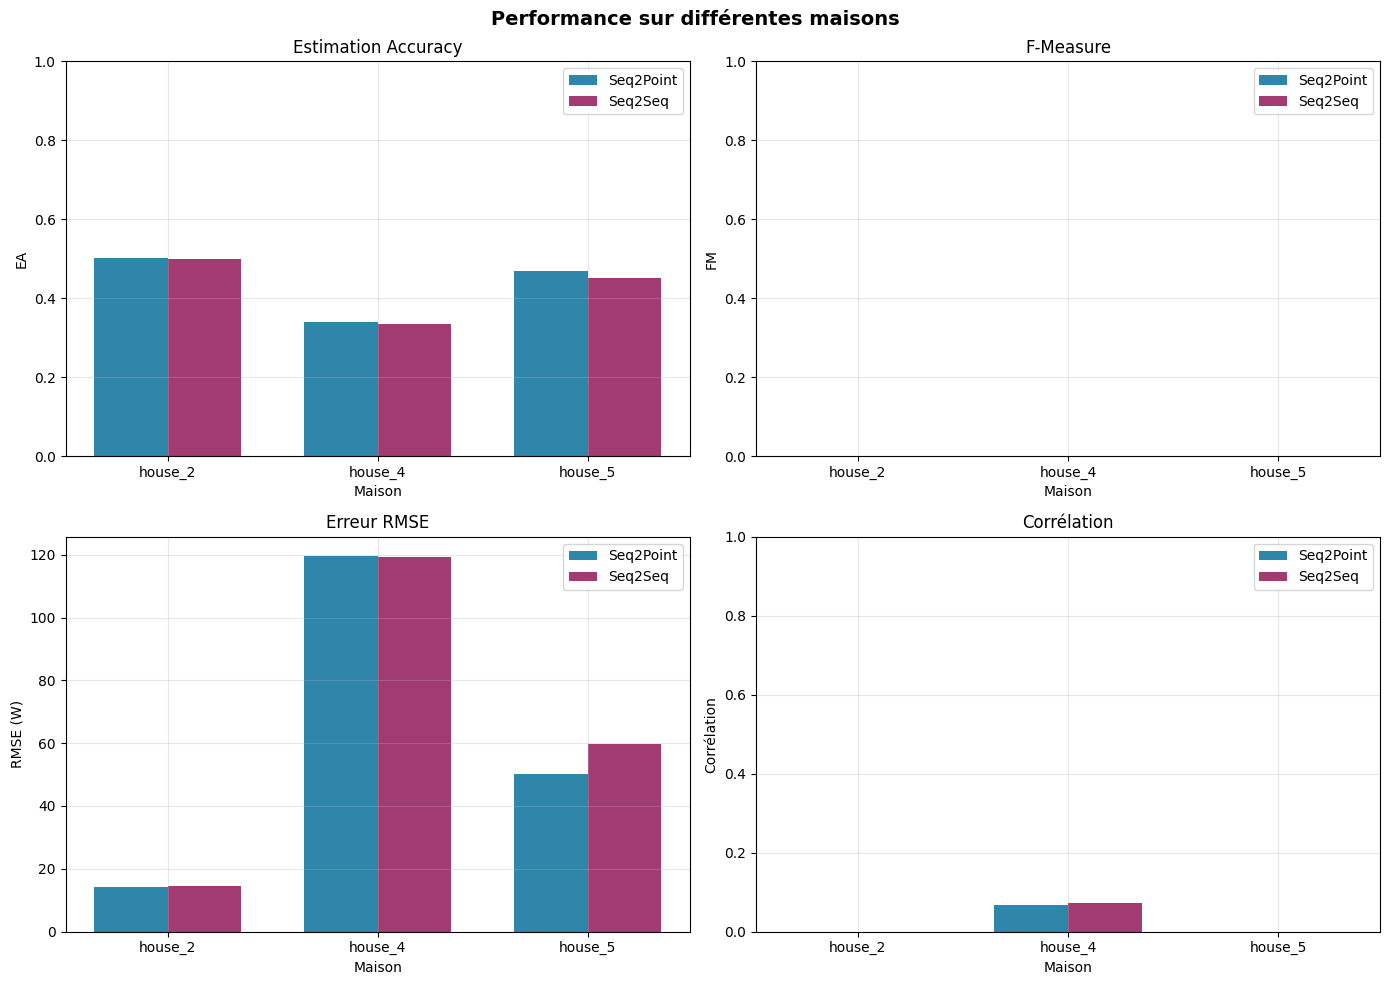

In [34]:
# ============================================================================
# CELL 105: VISUALISATION CORRIGÉE
# ============================================================================

def plot_comparison_simple_fixed(results_dict):
    """Visualisation simple des résultats"""
    if not results_dict:
        print("❌ Pas de résultats à visualiser")
        return
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    houses = list(results_dict.keys())
    x = np.arange(len(houses))
    width = 0.35
    
    # EA
    ax = axes[0, 0]
    ea_point = [results_dict[h]['seq2point']['ea'] for h in houses]
    ea_seq = [results_dict[h]['seq2seq']['ea'] for h in houses]
    
    ax.bar(x - width/2, ea_point, width, label='Seq2Point', color='#2E86AB')
    ax.bar(x + width/2, ea_seq, width, label='Seq2Seq', color='#A23B72')
    ax.set_xlabel('Maison')
    ax.set_ylabel('EA')
    ax.set_title('Estimation Accuracy')
    ax.set_xticks(x)
    ax.set_xticklabels(houses)
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_ylim([0, 1])
    
    # FM
    ax = axes[0, 1]
    fm_point = [results_dict[h]['seq2point']['fm'] for h in houses]
    fm_seq = [results_dict[h]['seq2seq']['fm'] for h in houses]
    
    ax.bar(x - width/2, fm_point, width, label='Seq2Point', color='#2E86AB')
    ax.bar(x + width/2, fm_seq, width, label='Seq2Seq', color='#A23B72')
    ax.set_xlabel('Maison')
    ax.set_ylabel('FM')
    ax.set_title('F-Measure')
    ax.set_xticks(x)
    ax.set_xticklabels(houses)
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_ylim([0, 1])
    
    # RMSE
    ax = axes[1, 0]
    rmse_point = [results_dict[h]['seq2point']['rmse'] for h in houses]
    rmse_seq = [results_dict[h]['seq2seq']['rmse'] for h in houses]
    
    ax.bar(x - width/2, rmse_point, width, label='Seq2Point', color='#2E86AB')
    ax.bar(x + width/2, rmse_seq, width, label='Seq2Seq', color='#A23B72')
    ax.set_xlabel('Maison')
    ax.set_ylabel('RMSE (W)')
    ax.set_title('Erreur RMSE')
    ax.set_xticks(x)
    ax.set_xticklabels(houses)
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # Corrélation
    ax = axes[1, 1]
    corr_point = [results_dict[h]['seq2point']['corr'] for h in houses]
    corr_seq = [results_dict[h]['seq2seq']['corr'] for h in houses]
    
    ax.bar(x - width/2, corr_point, width, label='Seq2Point', color='#2E86AB')
    ax.bar(x + width/2, corr_seq, width, label='Seq2Seq', color='#A23B72')
    ax.set_xlabel('Maison')
    ax.set_ylabel('Corrélation')
    ax.set_title('Corrélation')
    ax.set_xticks(x)
    ax.set_xticklabels(houses)
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_ylim([0, 1])
    
    plt.suptitle('Performance sur différentes maisons', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Afficher les résultats
if 'kettle_models' in locals() and available_houses:
    # Collecter les résultats
    all_results = {}
    for house in available_houses:
        result = test_on_any_house_fixed(
            kettle_models, house,
            'Kettle', KETTLE_CONFIG['meter'], KETTLE_CONFIG['threshold']
        )
        if result:
            all_results[house] = result
    
    if all_results:
        plot_comparison_simple_fixed(all_results)

In [36]:
# ============================================================================
# CELL 106: INTERFACE SIMPLE
# ============================================================================

def test_house_simple(house_key):
    """Test simple sur une maison"""
    if house_key in available_houses:
        test_on_any_house_fixed(
            kettle_models, house_key,
            'Kettle', KETTLE_CONFIG['meter'], KETTLE_CONFIG['threshold']
        )
    else:
        print(f"❌ {house_key} non disponible. Maisons disponibles: {available_houses}")

print("\n" + "="*70)
print("COMMENT UTILISER:")
print("="*70)
print(f"\n🏠 Maisons disponibles: {available_houses}")
print("\n📌 Pour tester sur house_2:")
print(">>> test_house_simple('house_2')")
print("\n📌 Pour tester sur house_5:")
print(">>> test_house_simple('house_5')")


COMMENT UTILISER:

🏠 Maisons disponibles: ['house_2', 'house_4', 'house_5']

📌 Pour tester sur house_2:
>>> test_house_simple('house_2')

📌 Pour tester sur house_5:
>>> test_house_simple('house_5')


In [37]:
# ============================================================================
# CELL 200: VISUALISATION GROUND TRUTH VS PRÉDICTIONS
# ============================================================================

def plot_ground_truth_vs_predictions(models_dict, house_key, appliance_name, meter_key, threshold, duration_minutes=120):
    """
    Visualise Ground Truth vs Prédictions pour Seq2Point et Seq2Seq
    
    Paramètres:
    - models_dict: Dictionnaire contenant les modèles
    - house_key: 'house_2', 'house_5', etc.
    - appliance_name: Nom de l'appliance ('Kettle')
    - meter_key: 'meter5' pour kettle
    - threshold: Seuil ON/OFF (2000 pour kettle)
    - duration_minutes: Durée de visualisation en minutes (défaut: 120 = 2 heures)
    """
    
    print("="*70)
    print(f"VISUALISATION - {house_key.upper()} - {appliance_name}")
    print("="*70)
    
    # Charger la maison
    if not set_test_house(house_key):
        print(f"❌ Impossible de charger {house_key}")
        return
    
    if DATA_TEST is None or len(DATA_TEST['test_df']) == 0:
        print(f"❌ Pas de données pour {house_key}")
        return
    
    test_df = DATA_TEST['test_df']
    
    # Vérifier que le compteur existe
    if meter_key not in test_df.columns:
        print(f"❌ Compteur {meter_key} non trouvé")
        print(f"   Compteurs disponibles: {test_df.columns.tolist()}")
        return
    
    # Prendre un échantillon avec activité
    true_vals = test_df[meter_key].values
    
    # Chercher une période avec activité
    active_idx = np.where(true_vals > threshold)[0]
    
    # Nombre de points pour la durée demandée (6 secondes par point)
    n_points = int(duration_minutes * 60 / 6)
    
    if len(active_idx) > 0:
        # Prendre une période autour d'une activation
        center = active_idx[len(active_idx) // 2]
        start_i = max(0, center - n_points // 2)
    else:
        # Si pas d'activation, prendre le début
        print("⚠️  Aucune activation détectée, prise du début")
        start_i = 0
    
    if start_i + n_points > len(true_vals):
        start_i = max(0, len(true_vals) - n_points)
    end_i = start_i + n_points
    
    # Extraire les données
    true_segment = true_vals[start_i:end_i]
    time_minutes = np.arange(len(true_segment)) * 6 / 60  # Conversion en minutes
    
    # Signal principal (somme des compteurs)
    mains_vals = test_df[DATA_TEST['monitored_meters']].sum(axis=1).values[start_i:end_i]
    mains_s = pd.Series(mains_vals)
    
    # Faire les prédictions
    print("\n📊 Génération des prédictions...")
    
    predictions = {}
    metrics = {}
    
    for model_type in ['seq2point', 'seq2seq']:
        if model_type not in models_dict:
            print(f"⚠️  Modèle {model_type} non disponible")
            continue
        
        print(f"  → Prédiction avec {model_type}...")
        
        # Prédire
        pred = predict_appliance(mains_s, models_dict[model_type], model_type)
        pred = np.clip(pred, 0, None)  # Pas de valeurs négatives
        
        # Ajuster la longueur
        min_len = min(len(true_segment), len(pred))
        pred = pred[:min_len]
        true_adjusted = true_segment[:min_len]
        time_adjusted = time_minutes[:min_len]
        
        # Calculer les métriques
        ea = NILMMetrics.estimation_accuracy(true_adjusted, pred)
        fm = NILMMetrics.f_measure(true_adjusted, pred, threshold)
        rmse = np.sqrt(np.mean((true_adjusted - pred) ** 2))
        
        predictions[model_type] = {
            'values': pred,
            'time': time_adjusted,
            'ea': ea,
            'fm': fm,
            'rmse': rmse
        }
        
        metrics[model_type] = {'ea': ea, 'fm': fm, 'rmse': rmse}
    
    if not predictions:
        print("❌ Aucune prédiction disponible")
        return
    
    # Créer la visualisation
    fig = plt.figure(figsize=(16, 12))
    
    # 1. Graphique principal - Comparaison des trois courbes
    ax1 = plt.subplot(3, 1, 1)
    
    # Ground Truth
    ax1.plot(time_adjusted, true_adjusted, 
             color='black', linewidth=2, label='Ground Truth', alpha=0.9)
    
    # Seuil
    ax1.axhline(y=threshold, color='red', linestyle='--', 
                linewidth=1.5, alpha=0.7, label=f'Seuil ({threshold}W)')
    
    ax1.set_ylabel('Puissance (W)', fontsize=12)
    ax1.set_title(f'{house_key} - Ground Truth', fontweight='bold', fontsize=14)
    ax1.legend(loc='upper right', fontsize=10)
    ax1.grid(True, alpha=0.3)
    ax1.set_xlim([0, duration_minutes])
    ax1.set_ylim([0, max(true_adjusted.max(), threshold*1.2)])
    
    # 2. Seq2Point vs Ground Truth
    ax2 = plt.subplot(3, 1, 2)
    
    ax2.plot(time_adjusted, true_adjusted, 
             color='black', linewidth=1.5, alpha=0.5, label='Ground Truth')
    ax2.plot(predictions['seq2point']['time'], predictions['seq2point']['values'], 
             color='#2E86AB', linewidth=2, label='Seq2Point', alpha=0.8)
    ax2.axhline(y=threshold, color='red', linestyle='--', linewidth=1, alpha=0.5)
    
    ax2.set_ylabel('Puissance (W)', fontsize=12)
    ax2.set_title(f'Seq2Point (EA={metrics["seq2point"]["ea"]:.3f}, FM={metrics["seq2point"]["fm"]:.3f}, RMSE={metrics["seq2point"]["rmse"]:.1f}W)', 
                  fontweight='bold', fontsize=12)
    ax2.legend(loc='upper right', fontsize=10)
    ax2.grid(True, alpha=0.3)
    ax2.set_xlim([0, duration_minutes])
    ax2.set_ylim([0, max(true_adjusted.max(), predictions['seq2point']['values'].max(), threshold*1.2)])
    
    # 3. Seq2Seq vs Ground Truth
    ax3 = plt.subplot(3, 1, 3)
    
    ax3.plot(time_adjusted, true_adjusted, 
             color='black', linewidth=1.5, alpha=0.5, label='Ground Truth')
    ax3.plot(predictions['seq2seq']['time'], predictions['seq2seq']['values'], 
             color='#A23B72', linewidth=2, label='Seq2Seq', alpha=0.8)
    ax3.axhline(y=threshold, color='red', linestyle='--', linewidth=1, alpha=0.5)
    
    ax3.set_xlabel('Temps (minutes)', fontsize=12)
    ax3.set_ylabel('Puissance (W)', fontsize=12)
    ax3.set_title(f'Seq2Seq (EA={metrics["seq2seq"]["ea"]:.3f}, FM={metrics["seq2seq"]["fm"]:.3f}, RMSE={metrics["seq2seq"]["rmse"]:.1f}W)', 
                  fontweight='bold', fontsize=12)
    ax3.legend(loc='upper right', fontsize=10)
    ax3.grid(True, alpha=0.3)
    ax3.set_xlim([0, duration_minutes])
    ax3.set_ylim([0, max(true_adjusted.max(), predictions['seq2seq']['values'].max(), threshold*1.2)])
    
    plt.suptitle(f'Comparaison des prédictions - {appliance_name} - {house_key}', 
                 fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    
    # Sauvegarder
    fname = f'{appliance_name.lower()}_{house_key}_comparison.png'
    fig.savefig(fname, dpi=150, bbox_inches='tight')
    print(f"\n💾 Graphique sauvegardé: {fname}")
    plt.show()
    
    # Afficher un résumé des métriques
    print("\n" + "="*50)
    print("RÉSUMÉ DES PERFORMANCES")
    print("="*50)
    print(f"{'Modèle':<12} {'EA':<8} {'FM':<8} {'RMSE':<8}")
    print("-"*36)
    for model_type, m in metrics.items():
        print(f"{model_type:<12} {m['ea']:.4f}  {m['fm']:.4f}  {m['rmse']:.1f}W")
    
    return predictions, metrics

In [39]:
# ============================================================================
# CELL 201: VISUALISATION AVEC ZOOM SUR LES ÉVÉNEMENTS
# ============================================================================

def plot_zoomed_events(models_dict, house_key, appliance_name, meter_key, threshold, n_events=3):
    """
    Visualise plusieurs événements individuels (activations) zoomés
    """
    
    print("="*70)
    print(f"ZOOM SUR LES ÉVÉNEMENTS - {house_key.upper()}")
    print("="*70)
    
    # Charger la maison
    if not set_test_house(house_key):
        print(f"❌ Impossible de charger {house_key}")
        return
    
    if DATA_TEST is None or len(DATA_TEST['test_df']) == 0:
        print(f"❌ Pas de données pour {house_key}")
        return
    
    test_df = DATA_TEST['test_df']
    
    if meter_key not in test_df.columns:
        print(f"❌ Compteur {meter_key} non trouvé")
        return
    
    true_vals = test_df[meter_key].values
    
    # Trouver les événements (périodes où la puissance > seuil)
    above_threshold = true_vals > threshold
    changes = np.diff(np.concatenate(([0], above_threshold.astype(int), [0])))
    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0]
    
    events = list(zip(starts, ends))
    
    if len(events) == 0:
        print("❌ Aucun événement détecté")
        return
    
    print(f"📊 {len(events)} événements détectés")
    
    # Prendre les n_events premiers événements (ou moins)
    events_to_show = events[:min(n_events, len(events))]
    
    # Créer une figure pour chaque événement
    for i, (start, end) in enumerate(events_to_show):
        # Prendre un contexte autour de l'événement
        context = 50  # points avant/après
        plot_start = max(0, start - context)
        plot_end = min(len(true_vals), end + context)
        
        true_segment = true_vals[plot_start:plot_end]
        time_seconds = np.arange(len(true_segment)) * 6  # en secondes
        
        # Signal principal
        mains_vals = test_df[DATA_TEST['monitored_meters']].sum(axis=1).values[plot_start:plot_end]
        mains_s = pd.Series(mains_vals)
        
        # Prédictions
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))
        
        for idx, model_type in enumerate(['seq2point', 'seq2seq']):
            if model_type not in models_dict:
                continue
            
            pred = predict_appliance(mains_s, models_dict[model_type], model_type)
            pred = np.clip(pred, 0, None)
            
            # Ajuster les longueurs
            min_len = min(len(true_segment), len(pred))
            true_adj = true_segment[:min_len]
            pred_adj = pred[:min_len]
            time_adj = time_seconds[:min_len]
            
            # Calculer métriques pour cet événement
            ea = NILMMetrics.estimation_accuracy(true_adj, pred_adj)
            fm = NILMMetrics.f_measure(true_adj, pred_adj, threshold)
            
            ax = axes[idx]
            ax.plot(time_adj, true_adj, 'k-', linewidth=2, label='Ground Truth')
            ax.plot(time_adj, pred_adj, '--', linewidth=2, 
                   label=f'{model_type} (EA={ea:.3f}, FM={fm:.3f})',
                   color='#2E86AB' if model_type == 'seq2point' else '#A23B72')
            ax.axhline(y=threshold, color='r', linestyle=':', alpha=0.5, label=f'Seuil')
            ax.axvline(x=(start-plot_start)*6, color='g', linestyle=':', alpha=0.5)
            ax.axvline(x=(end-plot_start)*6, color='g', linestyle=':', alpha=0.5)
            
            ax.set_xlabel('Temps (secondes)')
            ax.set_ylabel('Puissance (W)')
            ax.set_title(f'{model_type} - Événement {i+1}')
            ax.legend(fontsize=8)
            ax.grid(True, alpha=0.3)
        
        plt.suptitle(f'{house_key} - Événement {i+1} ({(end-start)*6:.0f} secondes)', 
                    fontweight='bold')
        plt.tight_layout()
        plt.show()


In [40]:
# ============================================================================
# CELL 202: VISUALISATION STATISTIQUE (BOÎTES À MOUSTACHES)
# ============================================================================

def plot_error_distribution(models_dict, house_key, appliance_name, meter_key, threshold, n_samples=1000):
    """
    Visualise la distribution des erreurs de prédiction
    """
    
    print("="*70)
    print(f"DISTRIBUTION DES ERREURS - {house_key.upper()}")
    print("="*70)
    
    # Charger la maison
    if not set_test_house(house_key):
        print(f"❌ Impossible de charger {house_key}")
        return
    
    if DATA_TEST is None or len(DATA_TEST['test_df']) == 0:
        print(f"❌ Pas de données pour {house_key}")
        return
    
    test_df = DATA_TEST['test_df']
    
    if meter_key not in test_df.columns:
        print(f"❌ Compteur {meter_key} non trouvé")
        return
    
    # Prendre un échantillon
    true_vals = test_df[meter_key].values
    if len(true_vals) > n_samples:
        indices = np.random.choice(len(true_vals), n_samples, replace=False)
        indices.sort()
    else:
        indices = np.arange(len(true_vals))
    
    true_sample = true_vals[indices]
    mains_vals = test_df[DATA_TEST['monitored_meters']].sum(axis=1).values[indices]
    mains_s = pd.Series(mains_vals)
    
    # Prédictions et erreurs
    errors = {}
    predictions = {}
    
    for model_type in ['seq2point', 'seq2seq']:
        if model_type not in models_dict:
            continue
        
        pred = predict_appliance(mains_s, models_dict[model_type], model_type)
        pred = np.clip(pred, 0, None)
        
        min_len = min(len(true_sample), len(pred))
        errors[model_type] = true_sample[:min_len] - pred[:min_len]
        predictions[model_type] = pred[:min_len]
    
    # Créer la visualisation
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    
    # 1. Distribution des erreurs
    ax = axes[0, 0]
    for model_type, color in [('seq2point', '#2E86AB'), ('seq2seq', '#A23B72')]:
        if model_type in errors:
            ax.hist(errors[model_type], bins=50, alpha=0.5, 
                   label=model_type, color=color, density=True)
    ax.axvline(x=0, color='red', linestyle='--', linewidth=1)
    ax.set_xlabel('Erreur (W)')
    ax.set_ylabel('Densité')
    ax.set_title('Distribution des erreurs')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # 2. Boîtes à moustaches
    ax = axes[0, 1]
    error_data = [errors[mt] for mt in ['seq2point', 'seq2seq'] if mt in errors]
    labels = [mt for mt in ['seq2point', 'seq2seq'] if mt in errors]
    bp = ax.boxplot(error_data, labels=labels, patch_artist=True)
    
    colors = ['#2E86AB', '#A23B72']
    for patch, color in zip(bp['boxes'], colors[:len(error_data)]):
        patch.set_facecolor(color)
        patch.set_alpha(0.5)
    
    ax.axhline(y=0, color='red', linestyle='--', linewidth=1)
    ax.set_ylabel('Erreur (W)')
    ax.set_title('Boîtes à moustaches des erreurs')
    ax.grid(True, alpha=0.3)
    
    # 3. Scatter plot prédictions vs ground truth
    ax = axes[1, 0]
    for model_type, color in [('seq2point', '#2E86AB'), ('seq2seq', '#A23B72')]:
        if model_type in predictions:
            ax.scatter(true_sample[:len(predictions[model_type])], 
                      predictions[model_type], 
                      alpha=0.3, label=model_type, color=color, s=10)
    
    # Ligne parfaite
    max_val = max(true_sample.max(), 
                  max([p.max() for p in predictions.values() if len(p) > 0]))
    ax.plot([0, max_val], [0, max_val], 'r--', linewidth=1, label='Parfait')
    
    ax.set_xlabel('Ground Truth (W)')
    ax.set_ylabel('Prédictions (W)')
    ax.set_title('Prédictions vs Ground Truth')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # 4. Métriques récapitulatives
    ax = axes[1, 1]
    ax.axis('tight')
    ax.axis('off')
    
    table_data = []
    for model_type in ['seq2point', 'seq2seq']:
        if model_type in errors:
            mae = np.mean(np.abs(errors[model_type]))
            rmse = np.sqrt(np.mean(errors[model_type]**2))
            std = np.std(errors[model_type])
            table_data.append([
                model_type,
                f"{mae:.1f}",
                f"{rmse:.1f}",
                f"{std:.1f}",
                f"{errors[model_type].min():.1f}",
                f"{errors[model_type].max():.1f}"
            ])
    
    columns = ['Modèle', 'MAE', 'RMSE', 'Std', 'Min', 'Max']
    ax.table(cellText=table_data, colLabels=columns, 
             cellLoc='center', loc='center',
             colColours=['#f2f2f2']*6)
    ax.set_title('Statistiques des erreurs', fontweight='bold')
    
    plt.suptitle(f'Analyse des erreurs - {house_key}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


In [43]:
# ============================================================================
# CELL 203: EXEMPLES D'UTILISATION
# ============================================================================

print("\n" + "="*70)
print("COMMENT UTILISER LES FONCTIONS DE VISUALISATION")
print("="*70)
print("""
📊 1. Visualisation standard (2 heures):
    >>> plot_ground_truth_vs_predictions(kettle_models, 'house_2', 'Kettle', 'meter5', 2000)

📊 2. Visualisation avec durée personnalisée:
    >>> plot_ground_truth_vs_predictions(kettle_models, 'house_2', 'Kettle', 'meter5', 2000, duration_minutes=60)

📊 3. Zoom sur les événements individuels:
    >>> plot_zoomed_events(kettle_models, 'house_2', 'Kettle', 'meter5', 2000, n_events=3)

📊 4. Distribution des erreurs:
    >>> plot_error_distribution(kettle_models, 'house_2', 'Kettle', 'meter5', 2000)

📊 5. Pour house_5 (si disponible):
    >>> plot_ground_truth_vs_predictions(kettle_models, 'house_5', 'Kettle', 'meter5', 2000)
""")

# Exemple d'utilisation avec la première maison disponible
if 'available_houses' in dir() and available_houses:
    print(f"\n🏠 Maison recommandée pour test: {available_houses[0]}")
    print(f"\nPour visualiser immédiatement sur {available_houses[0]}:")
    print(f">>> plot_ground_truth_vs_predictions(kettle_models, '{available_houses[0]}', 'Kettle', 'meter5', 2000)")


COMMENT UTILISER LES FONCTIONS DE VISUALISATION

📊 1. Visualisation standard (2 heures):
    >>> plot_ground_truth_vs_predictions(kettle_models, 'house_2', 'Kettle', 'meter5', 2000)

📊 2. Visualisation avec durée personnalisée:
    >>> plot_ground_truth_vs_predictions(kettle_models, 'house_2', 'Kettle', 'meter5', 2000, duration_minutes=60)

📊 3. Zoom sur les événements individuels:
    >>> plot_zoomed_events(kettle_models, 'house_2', 'Kettle', 'meter5', 2000, n_events=3)

📊 4. Distribution des erreurs:
    >>> plot_error_distribution(kettle_models, 'house_2', 'Kettle', 'meter5', 2000)

📊 5. Pour house_5 (si disponible):
    >>> plot_ground_truth_vs_predictions(kettle_models, 'house_5', 'Kettle', 'meter5', 2000)


🏠 Maison recommandée pour test: house_2

Pour visualiser immédiatement sur house_2:
>>> plot_ground_truth_vs_predictions(kettle_models, 'house_2', 'Kettle', 'meter5', 2000)


LANCEMENT DES VISUALISATIONS
✅ Modèles disponibles
🏠 Maisons disponibles: ['house_2', 'house_4', 'house_5']

VISUALISATION 1: house_2 (2 heures)
VISUALISATION - HOUSE_2 - Kettle

CHANGEMENT MAISON DE TEST: house_5 → house_2

CHARGEMENT TEST: UKDALE-2 (maison 2)
Période test: 2013-05-01 → 2013-08-01

Chargement des compteurs monitorés:
  Lecture meter2... ✓ 2804685 points
  Lecture meter4... ✓ 2801065 points
  Lecture meter6... ✓ 2795349 points
  Lecture meter8... ✓ 2094523 points
  Lecture meter5... ✓ 2806036 points
  Lecture meter3... ✓ 2805646 points

Chargement d'autres compteurs (pour le bruit):
  Lecture meter1... ✓ 2780373 points
  Lecture meter7... ✓ 2094586 points
  Lecture meter9... ✓ 2080995 points
  Lecture meter10... ✓ 2089140 points
  Lecture meter11... ✓ 1878770 points
  Lecture meter12... ✓ 1686220 points
  Lecture meter13... ✓ 1687175 points
  Lecture meter14... ✓ 1687285 points
  Lecture meter15... ✓ 1685519 points
  Lecture meter16... ✓ 1685322 points

✅ 16 compteurs 

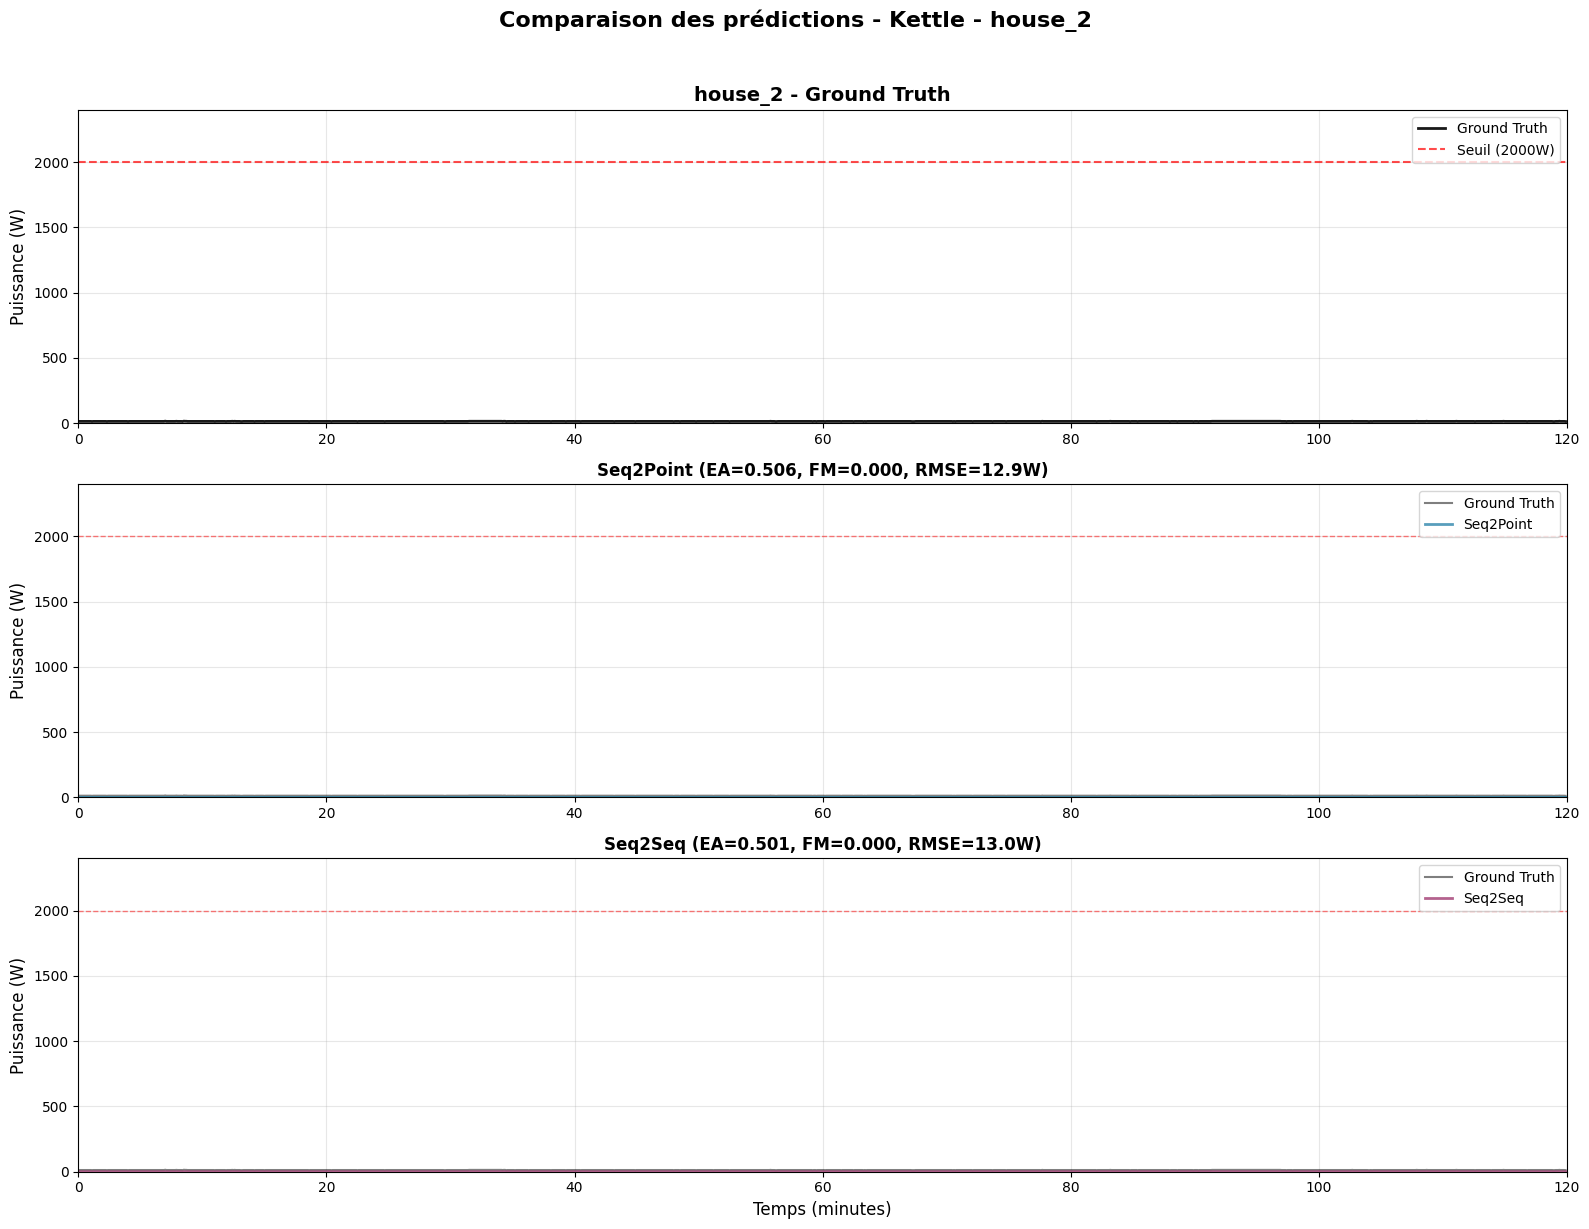


RÉSUMÉ DES PERFORMANCES
Modèle       EA       FM       RMSE    
------------------------------------
seq2point    0.5057  0.0000  12.9W
seq2seq      0.5010  0.0000  13.0W

VISUALISATION 2: house_5 (2 heures)
VISUALISATION - HOUSE_5 - Kettle

CHANGEMENT MAISON DE TEST: house_2 → house_5

CHARGEMENT TEST: UKDALE-5 (maison 5)
Période test: 2014-05-01 → 2014-08-01

Chargement des compteurs monitorés:
  Lecture meter2... ✓ 984881 points
  Lecture meter4... ✓ 1854414 points
  Lecture meter6... ✓ 1857061 points
  Lecture meter5... ✓ 1840507 points
  Lecture meter3... ✓ 1845649 points

Chargement d'autres compteurs (pour le bruit):
  Lecture meter1... ✓ 1763101 points
  Lecture meter7... ✓ 1851917 points
  Lecture meter8... ✓ 985653 points
  Lecture meter9... ✓ 1848688 points
  Lecture meter10... ✓ 985784 points
  Lecture meter11... ✓ 10215 points
  Lecture meter12... ✓ 985779 points
  Lecture meter13... ✓ 985600 points
  Lecture meter14... ✓ 985998 points
  Lecture meter15... ✓ 985856 points

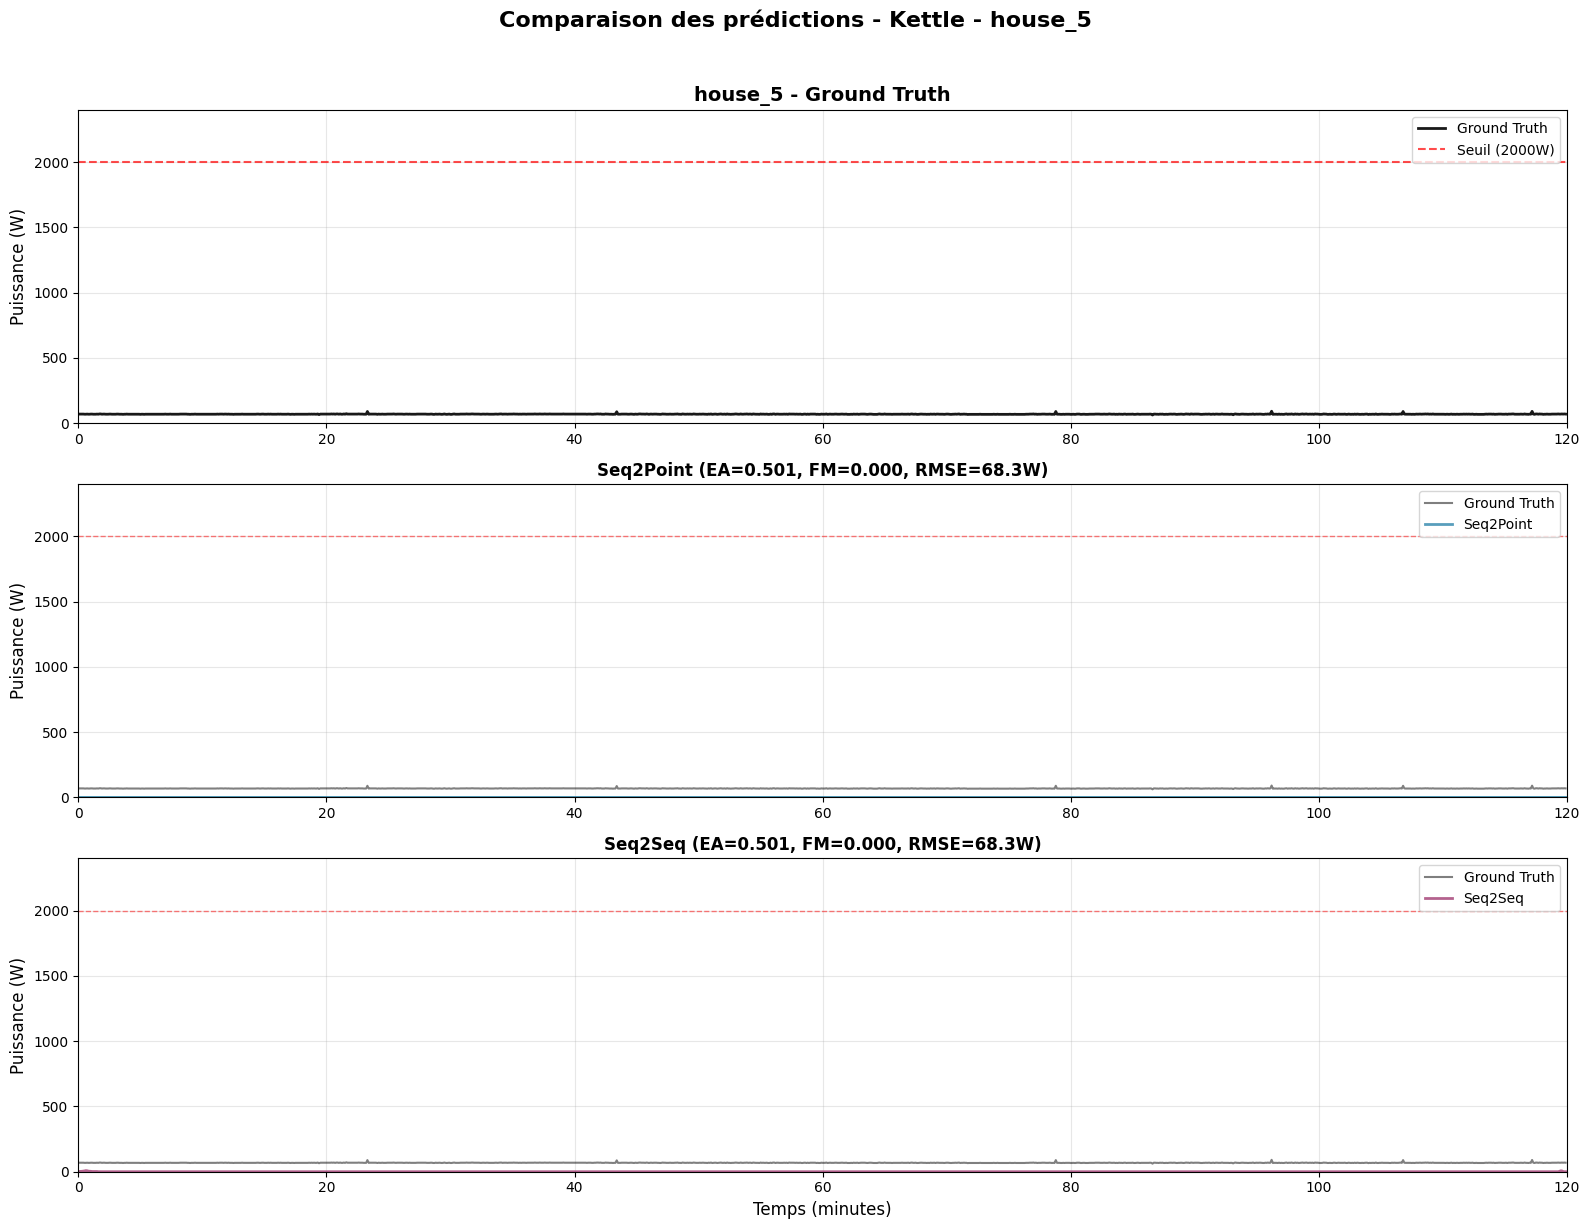


RÉSUMÉ DES PERFORMANCES
Modèle       EA       FM       RMSE    
------------------------------------
seq2point    0.5011  0.0000  68.3W
seq2seq      0.5006  0.0000  68.3W

VISUALISATION 3: Événements zoomés - house_2
ZOOM SUR LES ÉVÉNEMENTS - HOUSE_2

CHANGEMENT MAISON DE TEST: house_5 → house_2

CHARGEMENT TEST: UKDALE-2 (maison 2)
Période test: 2013-05-01 → 2013-08-01

Chargement des compteurs monitorés:
  Lecture meter2... ✓ 2804685 points
  Lecture meter4... ✓ 2801065 points
  Lecture meter6... ✓ 2795349 points
  Lecture meter8... ✓ 2094523 points
  Lecture meter5... ✓ 2806036 points
  Lecture meter3... ✓ 2805646 points

Chargement d'autres compteurs (pour le bruit):
  Lecture meter1... ✓ 2780373 points
  Lecture meter7... ✓ 2094586 points
  Lecture meter9... ✓ 2080995 points
  Lecture meter10... ✓ 2089140 points
  Lecture meter11... ✓ 1878770 points
  Lecture meter12... ✓ 1686220 points
  Lecture meter13... ✓ 1687175 points
  Lecture meter14... ✓ 1687285 points
  Lecture meter15.

In [44]:
# ============================================================================
# CELL 300: EXÉCUTION DES VISUALISATIONS
# ============================================================================

print("="*70)
print("LANCEMENT DES VISUALISATIONS")
print("="*70)

# Vérifier que les modèles sont chargés
if 'kettle_models' not in locals() or not kettle_models:
    print("❌ Les modèles ne sont pas chargés!")
    print("   Exécutez d'abord CELL 20 pour charger les modèles")
else:
    print("✅ Modèles disponibles")
    
    # Vérifier les maisons disponibles
    if 'available_houses' not in locals():
        # Définir la fonction si elle n'existe pas
        def get_available_houses():
            available = []
            test_houses = ['house_2', 'house_3', 'house_4', 'house_5']
            current = Config.TEST_HOUSE
            for house in test_houses:
                if set_test_house(house):
                    if DATA_TEST is not None and len(DATA_TEST['test_df']) > 0:
                        available.append(house)
            set_test_house(current)
            return available
        
        available_houses = get_available_houses()
    
    print(f"🏠 Maisons disponibles: {available_houses}")
    
    # 1. Visualisation sur house_2 (si disponible)
    if 'house_2' in available_houses:
        print("\n" + "="*70)
        print("VISUALISATION 1: house_2 (2 heures)")
        print("="*70)
        plot_ground_truth_vs_predictions(kettle_models, 'house_2', 'Kettle', 'meter5', 2000)
    else:
        print("\n❌ house_2 non disponible")
    
    # 2. Visualisation sur house_5 (si disponible)
    if 'house_5' in available_houses:
        print("\n" + "="*70)
        print("VISUALISATION 2: house_5 (2 heures)")
        print("="*70)
        plot_ground_truth_vs_predictions(kettle_models, 'house_5', 'Kettle', 'meter5', 2000)
    else:
        print("\n❌ house_5 non disponible")
    
    # 3. Événements zoomés sur la première maison disponible
    if available_houses:
        first_house = available_houses[0]
        print("\n" + "="*70)
        print(f"VISUALISATION 3: Événements zoomés - {first_house}")
        print("="*70)
        plot_zoomed_events(kettle_models, first_house, 'Kettle', 'meter5', 2000, n_events=3)

VISUALISATION - HOUSE_1 - Kettle

CHANGEMENT MAISON DE TEST: house_2 → house_1

CHARGEMENT TEST: UKDALE-1 (maison 1)
Période test: 2014-04-01 → 2014-05-01

Chargement des compteurs monitorés:
  Lecture meter2... ✓ 21281331 points
  Lecture meter4... ✓ 4539118 points
  Lecture meter6... ✓ 19819392 points
  Lecture meter3... ✓ 21281208 points
  Lecture meter5... ✓ 19555935 points
  Lecture meter7... ✓ 19763329 points

Chargement d'autres compteurs (pour le bruit):
  Lecture meter1... ✓ 21837636 points
  Lecture meter8... ✓ 21449386 points
  Lecture meter9... ✓ 19543268 points
  Lecture meter10... ✓ 18881051 points
  Lecture meter11... ✓ 19404267 points
  Lecture meter12... ✓ 19381298 points
  Lecture meter13... ✓ 19406625 points
  Lecture meter14... ✓ 4143648 points
  Lecture meter15... ✓ 4157704 points
  Lecture meter16... ✓ 13351860 points

✅ 16 compteurs chargés
Grille créée: 22950712 points

Test : 432000 échantillons

Statistiques des appliances (test):
  meter2: moy=15.5W  max=117.

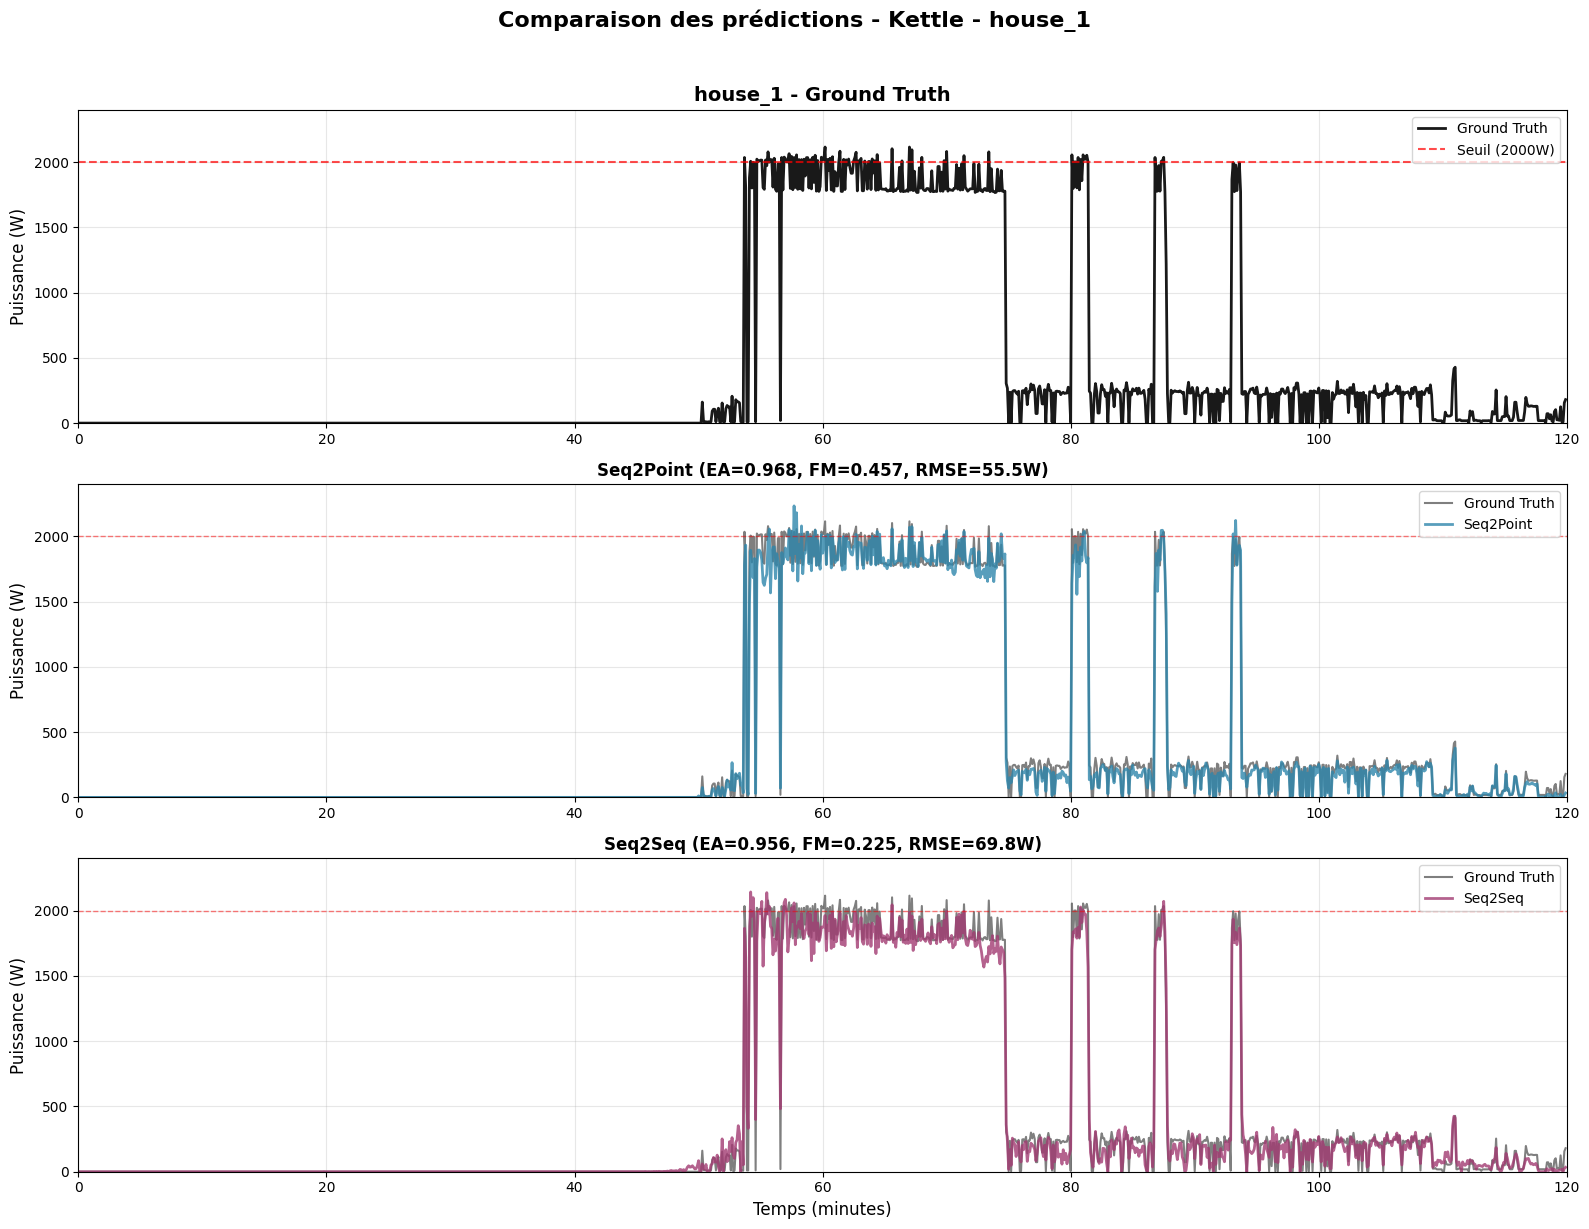


RÉSUMÉ DES PERFORMANCES
Modèle       EA       FM       RMSE    
------------------------------------
seq2point    0.9681  0.4571  55.5W
seq2seq      0.9562  0.2247  69.8W


({'seq2point': {'values': array([ 0.14803383,  0.14803383,  0.14803383, ...,  0.14803383,
          19.698446  , 33.70809   ], dtype=float32),
   'time': array([0.000e+00, 1.000e-01, 2.000e-01, ..., 1.197e+02, 1.198e+02,
          1.199e+02]),
   'ea': np.float32(0.96812475),
   'fm': np.float64(0.45714285714285713),
   'rmse': np.float32(55.459618)},
  'seq2seq': {'values': array([2.7035445e-02, 2.7035445e-02, 2.7035445e-02, ..., 0.0000000e+00,
          2.5328514e+01, 3.3447880e+01], dtype=float32),
   'time': array([0.000e+00, 1.000e-01, 2.000e-01, ..., 1.197e+02, 1.198e+02,
          1.199e+02]),
   'ea': np.float32(0.9562308),
   'fm': np.float64(0.2247191011235955),
   'rmse': np.float32(69.77832)}},
 {'seq2point': {'ea': np.float32(0.96812475),
   'fm': np.float64(0.45714285714285713),
   'rmse': np.float32(55.459618)},
  'seq2seq': {'ea': np.float32(0.9562308),
   'fm': np.float64(0.2247191011235955),
   'rmse': np.float32(69.77832)}})

In [45]:
# ============================================================================
# CELL 301: VISUALISATION HOUSE 2
# ============================================================================

plot_ground_truth_vs_predictions(kettle_models, 'house_1', 'Kettle', 'meter5', 2000)

ZOOM SUR LES ÉVÉNEMENTS - HOUSE_1

CHANGEMENT MAISON DE TEST: house_1 → house_1

CHARGEMENT TEST: UKDALE-1 (maison 1)
Période test: 2014-04-01 → 2014-05-01

Chargement des compteurs monitorés:
  Lecture meter2... ✓ 21281331 points
  Lecture meter4... ✓ 4539118 points
  Lecture meter6... ✓ 19819392 points
  Lecture meter3... ✓ 21281208 points
  Lecture meter5... ✓ 19555935 points
  Lecture meter7... ✓ 19763329 points

Chargement d'autres compteurs (pour le bruit):
  Lecture meter1... ✓ 21837636 points
  Lecture meter8... ✓ 21449386 points
  Lecture meter9... ✓ 19543268 points
  Lecture meter10... ✓ 18881051 points
  Lecture meter11... ✓ 19404267 points
  Lecture meter12... ✓ 19381298 points
  Lecture meter13... ✓ 19406625 points
  Lecture meter14... ✓ 4143648 points
  Lecture meter15... ✓ 4157704 points
  Lecture meter16... ✓ 13351860 points

✅ 16 compteurs chargés
Grille créée: 22950712 points

Test : 432000 échantillons

Statistiques des appliances (test):
  meter2: moy=15.5W  max=117

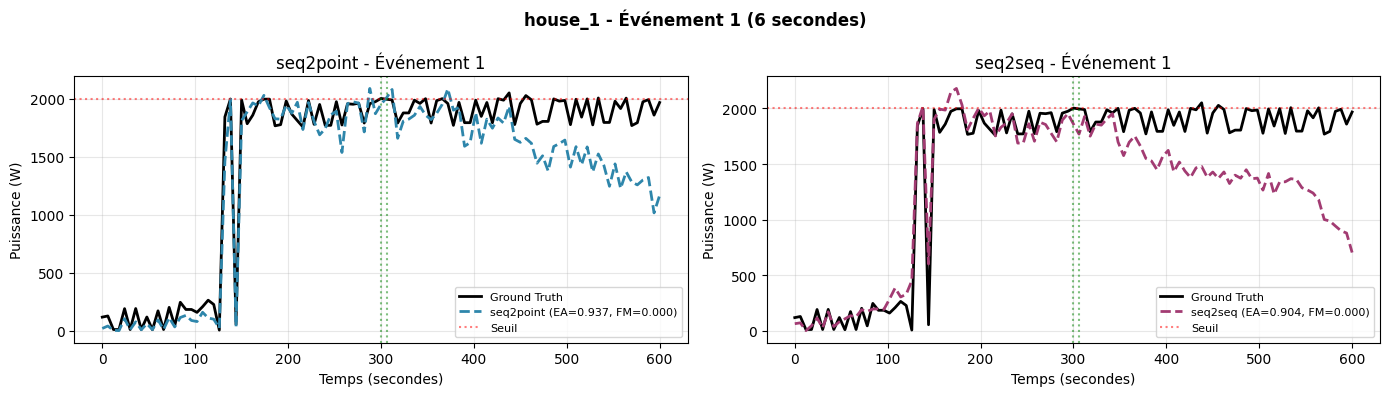

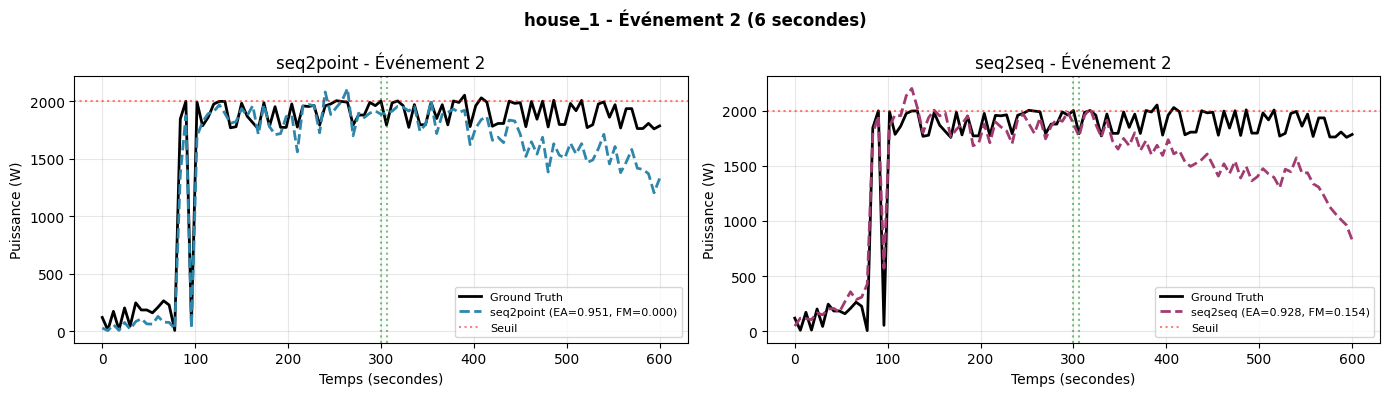

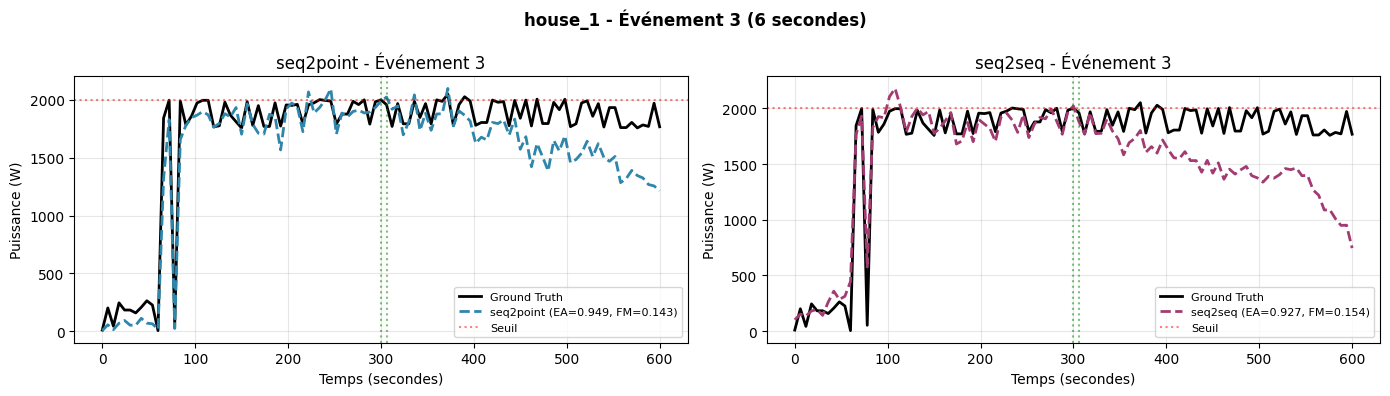

In [46]:
# ============================================================================
# CELL 303: ÉVÉNEMENTS ZOOMÉS
# ============================================================================

plot_zoomed_events(kettle_models, 'house_1', 'Kettle', 'meter5', 2000, n_events=3)

In [47]:
# ============================================================================
# CELL 400: SAUVEGARDE DES RÉSULTATS SANS RÉEXÉCUTION
# ============================================================================

import os
import shutil
import glob
from IPython.display import FileLink, display

print("="*70)
print("SAUVEGARDE DES RÉSULTATS")
print("="*70)

# 1. Créer un dossier pour regrouper tous les résultats
results_dir = '/kaggle/working/nilm_results'
os.makedirs(results_dir, exist_ok=True)

# 2. Sauvegarder les modèles (fichiers .keras)
print("\n📦 Modèles trouvés:")
model_files = glob.glob('/kaggle/working/*.keras')
for model_file in model_files:
    shutil.copy(model_file, results_dir)
    print(f"  ✅ {os.path.basename(model_file)}")

# 3. Sauvegarder les graphiques déjà générés
print("\n📊 Graphiques trouvés:")
image_files = glob.glob('/kaggle/working/*.png')
for img_file in image_files:
    shutil.copy(img_file, results_dir)
    print(f"  ✅ {os.path.basename(img_file)}")

# 4. Sauvegarder les métriques si disponibles
print("\n📈 Métriques disponibles:")
if 'kettle_models' in locals():
    print("  ✅ Modèles en mémoire")
    
    # Sauvegarder les infos des modèles
    model_info = {
        'seq2point': 'Disponible' if 'seq2point' in kettle_models else 'Non disponible',
        'seq2seq': 'Disponible' if 'seq2seq' in kettle_models else 'Non disponible'
    }
    
    # Sauvegarder dans un fichier texte
    with open(f'{results_dir}/model_info.txt', 'w') as f:
        f.write("INFORMATIONS DES MODÈLES\n")
        f.write("="*30 + "\n")
        f.write(f"Seq2Point: {model_info['seq2point']}\n")
        f.write(f"Seq2Seq: {model_info['seq2seq']}\n")
        
        if 'available_houses' in locals():
            f.write(f"\nMaisons disponibles: {available_houses}\n")
    
    print("  ✅ model_info.txt créé")

# 5. Compresser tous les résultats
print(f"\n🗜️ Compression des résultats...")
!tar -czf /kaggle/working/nilm_results.tar.gz -C /kaggle/working nilm_results
print("✅ Compression terminée: nilm_results.tar.gz")

# 6. Afficher les liens de téléchargement
print("\n" + "="*70)
print("📥 TÉLÉCHARGEMENT")
print("="*70)
print("\nCliquez sur les liens ci-dessous pour télécharger:")

print("\n📦 Tous les résultats (recommandé):")
display(FileLink('nilm_results.tar.gz', result_html_prefix="⬇️ "))

print("\n🖼️ Graphiques individuels:")
for img_file in image_files:
    fname = os.path.basename(img_file)
    display(FileLink(fname, result_html_prefix="⬇️ "))

SAUVEGARDE DES RÉSULTATS

📦 Modèles trouvés:
  ✅ model_Kettle_seq2seq_best.keras
  ✅ model_Kettle_seq2point_best.keras

📊 Graphiques trouvés:
  ✅ kettle_house_1_comparison.png
  ✅ kettle_house_2_comparison.png
  ✅ kettle_house_5_comparison.png

📈 Métriques disponibles:
  ✅ Modèles en mémoire
  ✅ model_info.txt créé

🗜️ Compression des résultats...
✅ Compression terminée: nilm_results.tar.gz

📥 TÉLÉCHARGEMENT

Cliquez sur les liens ci-dessous pour télécharger:

📦 Tous les résultats (recommandé):


/kaggle/working/nilm_results.tar.gz


🖼️ Graphiques individuels:


/kaggle/working/kettle_house_1_comparison.png

/kaggle/working/kettle_house_2_comparison.png

/kaggle/working/kettle_house_5_comparison.png

In [48]:
# ============================================================================
# CELL 401: À EXÉCUTER AVANT DE FAIRE "SAVE AND RUN"
# ============================================================================

print("="*70)
print("VÉRIFICATION PRÉ-SAVE")
print("="*70)

# Vérifier les cellules avec erreurs potentielles
print("\n🔍 Cellules à surveiller avant sauvegarde:")

# Liste des fonctions problématiques
problematic_functions = [
    'test_on_any_house',  # ancienne version
    'evaluate_on_current_test_house',  # ancienne version
    'plot_multi_house_comparison',  # utilise l'ancienne fonction
]

for func in problematic_functions:
    if func in dir():
        print(f"⚠️  Attention: La fonction '{func}' (ancienne version) est dans le namespace")
        print(f"   → Assurez-vous d'utiliser les versions '_fixed'")

print("\n✅ Cellules de sauvegarde des résultats ajoutées (CELL 400-401)")
print("   Exécutez CELL 400 MAINTENANT pour sauvegarder vos résultats actuels")

VÉRIFICATION PRÉ-SAVE

🔍 Cellules à surveiller avant sauvegarde:
⚠️  Attention: La fonction 'plot_multi_house_comparison' (ancienne version) est dans le namespace
   → Assurez-vous d'utiliser les versions '_fixed'

✅ Cellules de sauvegarde des résultats ajoutées (CELL 400-401)
   Exécutez CELL 400 MAINTENANT pour sauvegarder vos résultats actuels
